In [1]:
import pandas as pd
import numpy as np
import re
from textwrap import fill
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import matplotlib.ticker as mtick
import seaborn as sns

from scipy.cluster.hierarchy import linkage, leaves_list, cut_tree
from scipy.spatial.distance import pdist
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from sklearn.metrics import silhouette_score

In [2]:
raw_data = pd.read_csv('data/Food_Inspections_20261006.csv', dtype={'Zip': 'string', 'License #': 'string'})

data = raw_data.copy()
# Parse dates and retain observations from 2020 onwards
data['Inspection Date'] = pd.to_datetime(data['Inspection Date'])
data = data[data['Inspection Date'].dt.year >= 2020]

# Drop Location because latitude and longitude are available
data = data.drop(columns = 'Location')

# Standardise facility-type spelling without combining different business types
facility_name_mapping = {
    # Clear spelling errors
    'PUBLIC SHCOOL': 'PUBLIC SCHOOL',
    'CONVENIENT STORE': 'CONVENIENCE STORE',
    'CONVNIENCE STORE': 'CONVENIENCE STORE',
    'COMMISARY': 'COMMISSARY',
    'COMMIASARY': 'COMMISSARY',
    'MOBILPREPARED FOOD VENDOR': 'MOBILE PREPARED FOOD VENDOR',

    # Equivalent names
    'THEATRE': 'THEATER',
    'MOVIE THEATRE': 'MOVIE THEATER',
    'CANDY SHOP': 'CANDY STORE',
    'BANQUETS': 'BANQUET',
    'ROOF TOP': 'ROOFTOP',
    'ROOF TOPS': 'ROOFTOP',
    'ROOFTOPS': 'ROOFTOP',
    'TAVERN/BAR': 'TAVERN/BAR',  # Keep the mixed label
    'DAY CARE 2-14': 'DAYCARE 2-14',

    # Numbered and spelling variants of children's services
    "1023 CHILDERN'S SERVICES FACILITY": "CHILDREN'S SERVICES FACILITY",
    "1023-CHILDREN'S SERVICES FACILITY": "CHILDREN'S SERVICES FACILITY",
    "1023 CHILDREN'S SERVICES FACILITY": "CHILDREN'S SERVICES FACILITY",
    'CHILDRENS SERVICES FACILITY': "CHILDREN'S SERVICES FACILITY",

    # Same components in a different order
    'GROCERY/RESTAURANT': 'RESTAURANT/GROCERY STORE',
    'GROCERY STORE/RESTAURANT': 'RESTAURANT/GROCERY STORE',
    'GROCERY & RESTAURANT': 'RESTAURANT/GROCERY STORE',

    'GAS STATION/GROCERY': 'GROCERY STORE/GAS STATION',
    'GROCERY/GAS STATION': 'GROCERY STORE/GAS STATION',
    'CONVENIENCE/GAS STATION': 'GROCERY STORE/GAS STATION',

    'GROCERY & LIQUOR STORE': 'GROCERY/LIQUOR STORE',
    'LIQUOR/GROCERY': 'GROCERY/LIQUOR STORE',
    'LIQUOR/GROCERY STORE/BAR': 'GROCERY/LIQUOR STORE/BAR',

    'CATERING/BANQUET': 'BANQUET/CATERING'
}
data['Facility Type'] = data['Facility Type'].astype('string').fillna('UNKNOWN').str.strip().str.upper().str.replace(r'\s+', ' ', regex=True).replace(facility_name_mapping)
# Assign cleaned facility types to broader groups
facility_groups = {
    'Restaurant / Cafe': [
        'RESTAURANT',
        'COFFEE SHOP',
        'ICE CREAM SHOP',
        'ICE CREAM',
        'PALETERIA',
        'DONUT SHOP',
        'MILK TEA',
        'HOT DOG STATION',
        'JUICE BAR',
        'COFFEE AND/OR DRINKS',
        'COFFEE KIOSK',
        'SUSHI COUNTER',
        'JUICE AND SALAD BAR',
        'RESTAURANT(PROTEIN SHAKE BAR)',
        'NUTRITION SHAKES',
        'NUTRITION..SMOOTHIES/SHAKES',
        'SHAKES/TEAS',
        'CANDY/GELATO'
    ],

    'Grocery / Food Retail': [
        'GROCERY STORE',
        'CONVENIENCE STORE',
        'CONVENIENCE',
        'GROCERY STORE/GAS STATION',
        'GAS STATION',
        'GAS STATION STORE',
        'GAS STATION/FOOD',
        'GAS STATION/MINI MART',
        'GAS STATION/STORE',
        'GAS STATION FOOD STORE',
        'SERVICE GAS STATION',
        'GAS/MINI MART',
        'GROCERY/DOLLAR STORE',
        'DOLLAR STORE WITH GROCERY',
        'GROCERY STORE PLUS WIRELESS STORE',
        'GROCERY/DRUG STORE',
        'DRUG STORE/GROCERY',
        'CONVENIENCE/DRUG STORE',
        'GROCERY(SUSHI PREP)',
        'GROCERY/DELI',
        'BUTCHER, DELI',
        'BUTCHER SHOP',
        'CANDY STORE',
        'PACKAGED HEALTH FOODS',
        'HEALTH FOOD STORE'
    ],

    'School': [
        'SCHOOL',
        'CHARTER SCHOOL',
        'PRIVATE SCHOOL',
        'PUBLIC SCHOOL',
        'CHARTER SCHOOL CAFETERIA',
        'CPS (CHARTER)',
        'HIGH SCHOOL KITCHEN',
        'SCHOOL CAFETERIA',
        'UNIVERSITY CAFETERIA'
    ],

    "Childcare / Children's Services": [
        "CHILDREN'S SERVICES FACILITY",
        'DAYCARE ABOVE AND UNDER 2 YEARS',
        'DAYCARE (2 - 6 YEARS)',
        'DAYCARE (UNDER 2 YEARS)',
        'DAYCARE COMBO 1586',
        'DAYCARE',
        'DAYCARE 2 YRS TO 12 YRS',
        'DAYCARE 2-14',
        'DAYCARE NIGHT',
        'AFTER SCHOOL PROGRAM',
        'BEFORE AND AFTER SCHOOL PROGRAM'
    ],

    'Healthcare / Adult Care': [
        'HOSPITAL',
        'LONG TERM CARE',
        'NURSING HOME',
        'ASSISTED LIVING',
        'ASSISTED LIVING SENIOR CARE',
        'SUPPORTIVE LIVING',
        'ADULT DAYCARE',
        'SENIOR DAY CARE',
        'ADULT DAY SERVICE',
        'ADULT FAMILY CARE CENTER'
    ],

    'Bakery': [
        'BAKERY',
        'THC INFUSED BAKERY'
    ],

    'Catering / Shared Kitchen': [
        'CATERING',
        'SHARED KITCHEN',
        'SHARED KITCHEN USER (LONG TERM)',
        'SHARED KITCHEN USER (SHORT TERM)',
        'SHARED KITCHEN SUPPLEMENTAL',
        'COMMISSARY',
        'VENDING COMMISSARY',
        'CULINARY KITCHEN',
        'OUTREACH CULINARY KITCHEN',
        'TEST KITCHEN/ STORAGE'
    ],

    'Bar / Liquor': [
        'LIQUOR',
        'LIQUOR STORE',
        'TAVERN',
        'BAR',
        'TAVERN/BAR',
        'TAVERN/LIQUOR',
        'TAVERN/PACKAGED GOODS',
        'BREWERY',
        'DISTILLERY WITH TASTING ROOM'
    ],

    'Mobile Food': [
        'MOBILE FOOD PREPARER',
        'MOBILE FOOD DISPENSER',
        'MOBILE PREPARED FOOD VENDOR',
        'MOBILE FROZEN DESSERTS VENDOR',
        'MOBILE FOOD DESSERTS VENDOR',
        'MOBILE FOOD',
        'FROZEN DESSERT PUSHCARTS',
        'MOBILE PUSH CART'
    ],

    'Events / Hospitality': [
        'SPECIAL EVENT',
        'BANQUET HALL',
        'BANQUET',
        'BANQUET ROOM',
        'HOTEL',
        'HOSTEL',
        'ROOM SERVICE',
        'ROOFTOP',
        'WRIGLEY ROOFTOP',
        'STADIUM',
        'EVENT CENTER',
        'EVENT SPACE',
        'PRIVATE EVENT SPACE',
        'MUSIC VENUE',
        'THEATER',
        'MOVIE THEATER',
        'ENTERTAINMENT VENUE',
        'NIGHT CLUB',
        'AIRPORT LOUNGE',
        'LOUNGE/BANQUET HALL'
    ],

    'Mixed Facility': [
        'RESTAURANT/BAR',
        'RESTAURANT/GROCERY STORE',
        'GROCERY/BAKERY',
        'GROCERY/TAQUERIA',
        'GROCERY STORE/COOKING SCHOOL',
        'GAS STATION/RESTAURANT',
        'GROCERY/LIQUOR STORE',
        'GROCERY/LIQUOR STORE/BAR',
        'LIQUOR/COFFEE KIOSK',
        'JUICE BAR/GROCERY',
        'DELI/BAKERY',
        'CATERING/CAFE',
        'BANQUET HALL/CATERING',
        'BANQUET/CATERING',
        'CHURCH/SPECIAL EVENTS',
        'SLAUGHTER HOUSE/ GROCERY'
    ],

    'Other': [
        'OTHER'
    ],

    'Unknown': [
        'UNKNOWN'
    ]
}
# Build a replacement dictionary from original names to analysis groups
facility_group_mapping = {facility: group for group, facilities in facility_groups.items() for facility in facilities}
data['Facility Group'] = data['Facility Type'].replace(facility_group_mapping)
# Retain 870 unmapped records in overall analyses; exclude them from main facility-group comparisons
unclassified_mask = ~data['Facility Type'].isin(facility_group_mapping)
data.loc[unclassified_mask, 'Facility Group'] = 'Unclassified'

# For missing city values, review available coordinates to check whether records are in Chicago
data_city_nan = data[(data['City'].isna()) & (~data['Latitude'].isna()) & (~data['Longitude'].isna())].copy()
data_city_nan['Clean_city'] = 'CHICAGO'

# Check Chicago membership using both spelling and coordinates
city_mapping = {
    'Chicago': 'CHICAGO',
    'chicago': 'CHICAGO',
    'CHicago': 'CHICAGO',
    'CHICAGO.': 'CHICAGO',
    'CCHICAGO': 'CHICAGO',
    'CHICAGOO': 'CHICAGO',
    'CHICAGOCHICAGO': 'CHICAGO',
    'CHICAGOC': 'CHICAGO',
    'CH': 'CHICAGO',
    '312CHICAGO': 'CHICAGO',
    'chicagoBEDFORD PARK': 'CHICAGO'}
data['Clean_city'] = data['City'].map(lambda x: city_mapping[x] if x in city_mapping.keys() else x) # type: ignore
data = data[data['Clean_city'] == 'CHICAGO']
data = pd.concat([data, data_city_nan], axis = 0)
# Drop city and clean_city after cleaning because they are constant
data = data.drop(columns = ['City', 'Clean_city'])
# Drop State after the Chicago location check
data = data.drop(columns = 'State')

# Classify missing and All risk values as Unknown, alongside the three defined risk levels
data['Risk'] = data['Risk'].replace('All', pd.NA).fillna('Unknown')

# Strip surrounding whitespace from DBA Name, AKA Name and Address
for col in ['DBA Name', 'AKA Name', 'Address']:
    data[col] = data[col].str.strip()

# Treat zero license numbers as missing
data['License #'] = data['License #'].replace('0', pd.NA)

# Group inspection types
inspection_group_mapping = {
    # Routine inspections
    'Canvass': 'Routine Inspection',
    'Canvass Re-Inspection': 'Routine Re-Inspection',

    # License inspections
    'License': 'License Inspection',
    'License Re-Inspection': 'License Re-Inspection',

    # Complaint inspections
    'Complaint': 'Complaint Inspection',
    'Short Form Complaint': 'Complaint Inspection',
    'Complaint Re-Inspection': 'Complaint Re-Inspection',

    # Suspected food poisoning inspections
    'Suspected Food Poisoning': 'Suspected Food Poisoning',
    'Suspected Food Poisoning Re-inspection':
        'Suspected Food Poisoning Re-Inspection',

    # Special events and COVID-related complaints
    'Special Events (Festivals)': 'Special Event Inspection',
    'COVID COMPLAINT': 'COVID Complaint',

    # Explicitly incomplete inspections
    'Not Ready': 'Inspection Not Completed',
    'NO ENTRY': 'Inspection Not Completed',
    'OUT OF BUSINESS': 'Inspection Not Completed',

    # Keep categories with different meanings separate
    'Non-Inspection': 'Non-Inspection',
    'Recent Inspection': 'Recent Inspection',
    'Consultation': 'Consultation',
    'ASSESSMENT': 'Assessment'
}
data['Inspection Group'] = data['Inspection Type'].replace(inspection_group_mapping)

# Create a violation-level table linked by Inspection ID
data['Has Violation Text'] = data['Violations'].fillna('').str.strip().ne('')
violation_rows = []
parse_issues = []
for inspection_id, text in data.loc[(data['Has Violation Text'] == True), ['Inspection ID', 'Violations']].itertuples(index = False, name = None):
    for item in text.split('|'):
        item = item.strip()

        match = re.match(r'^(\d+)\.\s*(.+)$', item, flags=re.DOTALL)

        if match is None:
            parse_issues.append({'Inspection ID': inspection_id, 'Raw Item': item, 'Issue': 'Cannot get id or name'})
            continue

        code, content = match.groups()

        parts = re.split(r'\s*-\s*Comments\s*:\s*', content, maxsplit=1, flags=re.IGNORECASE)

        violation_rows.append({'Inspection ID': inspection_id, 'Violation Code': int(code), 'Violation Description': parts[0].strip(), 'Comments': parts[1].strip() if len(parts) == 2 else pd.NA, 'Raw Item': item})
violation = pd.DataFrame(violation_rows, columns = ['Inspection ID', 'Violation Code', 'Violation Description', 'Comments', 'Raw Item'])
# Deduplicate inspection-code pairs
violation_codes = violation[['Inspection ID', 'Violation Code']].drop_duplicates().reset_index(drop = True)
data = data.drop(columns = 'Violations')


# Reorder columns
data = data[['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type', 'Facility Group', 'Risk', 'Address', 'Zip', 'Inspection Date', 'Inspection Type', 'Inspection Group', 'Results', 'Has Violation Text', 'Latitude', 'Longitude']]

In [3]:
# Remove characters that are invalid in Excel
illegal_excel_chars = re.compile(r'[\x00-\x08\x0B-\x0C\x0E-\x1F]')

def clean_for_excel(df):
    result = df.copy()

    for col in result.select_dtypes(
        include=['object', 'string']
    ).columns:
        result[col] = result[col].map(
            lambda value: illegal_excel_chars.sub('', value)
            if isinstance(value, str) else value
        )

    return result

In [ ]:
# Save the cleaned tables
with pd.ExcelWriter('data/Chicago_Food_Inspections_Cleaned.xlsx', engine = 'openpyxl') as writer:
    clean_for_excel(data).to_excel(writer, sheet_name = 'Inspections', index = False)
    clean_for_excel(violation).to_excel(writer, sheet_name = 'Violation Details', index = False)
    clean_for_excel(violation_codes).to_excel(writer, sheet_name = 'Inspection Violation Codes', index = False)

Load the cleaned data from this point onwards


In [6]:
inspection = pd.read_excel('data/Chicago_Food_Inspections_Cleaned.xlsx', engine = 'openpyxl', sheet_name = 'Inspections')
violation = pd.read_excel('data/Chicago_Food_Inspections_Cleaned.xlsx', engine = 'openpyxl', sheet_name = 'Violation Details')
violation_codes = pd.read_excel('data/Chicago_Food_Inspections_Cleaned.xlsx', engine = 'openpyxl', sheet_name = 'Inspection Violation Codes')

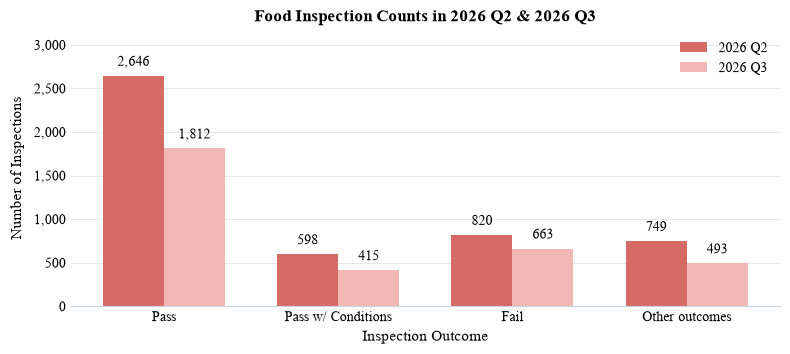

In [7]:
q2_2026 = inspection[(inspection['Inspection Date'].between('2026-04-01', '2026-06-30')) & ((inspection['Results'] == 'Pass') | (inspection['Results'] == 'Fail') | (inspection['Results'] == 'Pass w/ Conditions'))]
q3_2026 = inspection[(inspection['Inspection Date'].between('2026-07-01', '2026-09-30')) & ((inspection['Results'] == 'Pass') | (inspection['Results'] == 'Fail') | (inspection['Results'] == 'Pass w/ Conditions'))]

q2_2026_result = q2_2026.groupby('Results').agg(number = ('Inspection ID', 'nunique')).reset_index()
q3_2026_result = q3_2026.groupby('Results').agg(number = ('Inspection ID', 'nunique')).reset_index()

compare_table = pd.merge(q2_2026_result, q3_2026_result, how = 'inner', on = 'Results')

compare_table.columns = ['Results', '2026 Q2', '2026 Q3']

total = pd.DataFrame({'Results': ['Total'],
                      '2026 Q2': [inspection[inspection['Inspection Date'].between('2026-04-01', '2026-06-30')]['Inspection ID'].nunique()],
                      '2026 Q3': [inspection[inspection['Inspection Date'].between('2026-07-01', '2026-09-30')]['Inspection ID'].nunique()]})

other_outcome = pd.DataFrame({'Results': ['Other outcomes'],
                      '2026 Q2': [inspection[inspection['Inspection Date'].between('2026-04-01', '2026-06-30')]['Inspection ID'].nunique() - sum(compare_table['2026 Q2'])],
                      '2026 Q3': [inspection[inspection['Inspection Date'].between('2026-07-01', '2026-09-30')]['Inspection ID'].nunique()  - sum(compare_table['2026 Q3'])]})

compare_table = pd.concat([compare_table, other_outcome, total])


outcomes = ['Pass', 'Pass w/ Conditions', 'Fail', 'Other outcomes']
quarters = ['2026 Q2', '2026 Q3']

plot_data = compare_table.set_index('Results').loc[outcomes, quarters]

plt.rcParams['font.family'] = 'Times New Roman'

fig, ax = plt.subplots(figsize=(8, 4))

x = np.arange(len(outcomes))
width = 0.35
colors = ['#D66B66', '#F2B8B5']

for i, quarter in enumerate(quarters):
    values = plot_data[quarter]

    bars = ax.bar(x + (i - 0.5) * width, values, width = width, color = colors[i], label = quarter)

    ax.bar_label(bars, labels=[f'{value:,.0f}' for value in values], padding = 5, fontsize = 10, fontfamily = 'Times New Roman')

ax.set_xticks(x)
ax.set_xticklabels(['Pass', 'Pass w/ Conditions', 'Fail', 'Other outcomes'])

ax.set_xlabel('Inspection Outcome', fontsize = 11, fontfamily = 'Times New Roman')
ax.set_ylabel('Number of Inspections', fontsize = 11, fontfamily = 'Times New Roman')

ax.set_ylim(0, plot_data.max().max() * 1.2)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x: ,.0f}'))

# ax.set_title(
#     'Food Inspection Counts by Outcome and Quarter\n'
#     'Chicago, 2026 Q2–Q3',
#     loc='left',
#     fontsize=14,
#     fontweight='bold',
#     pad=18
# )

ax.legend(frameon = False, fontsize = 10)

ax.set_axisbelow(True)
ax.grid(axis = 'y', color = '#E5E7EB', linewidth = 0.7)

for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)

ax.spines['bottom'].set_color('#CBD5E1')
ax.tick_params(axis = 'both', length = 0)

plt.title('Food Inspection Counts in 2026 Q2 & 2026 Q3', fontdict = {'fontweight': 'bold'})


plt.tight_layout(rect = [0, 0.09, 1, 1]) # type: ignore
plt.show()

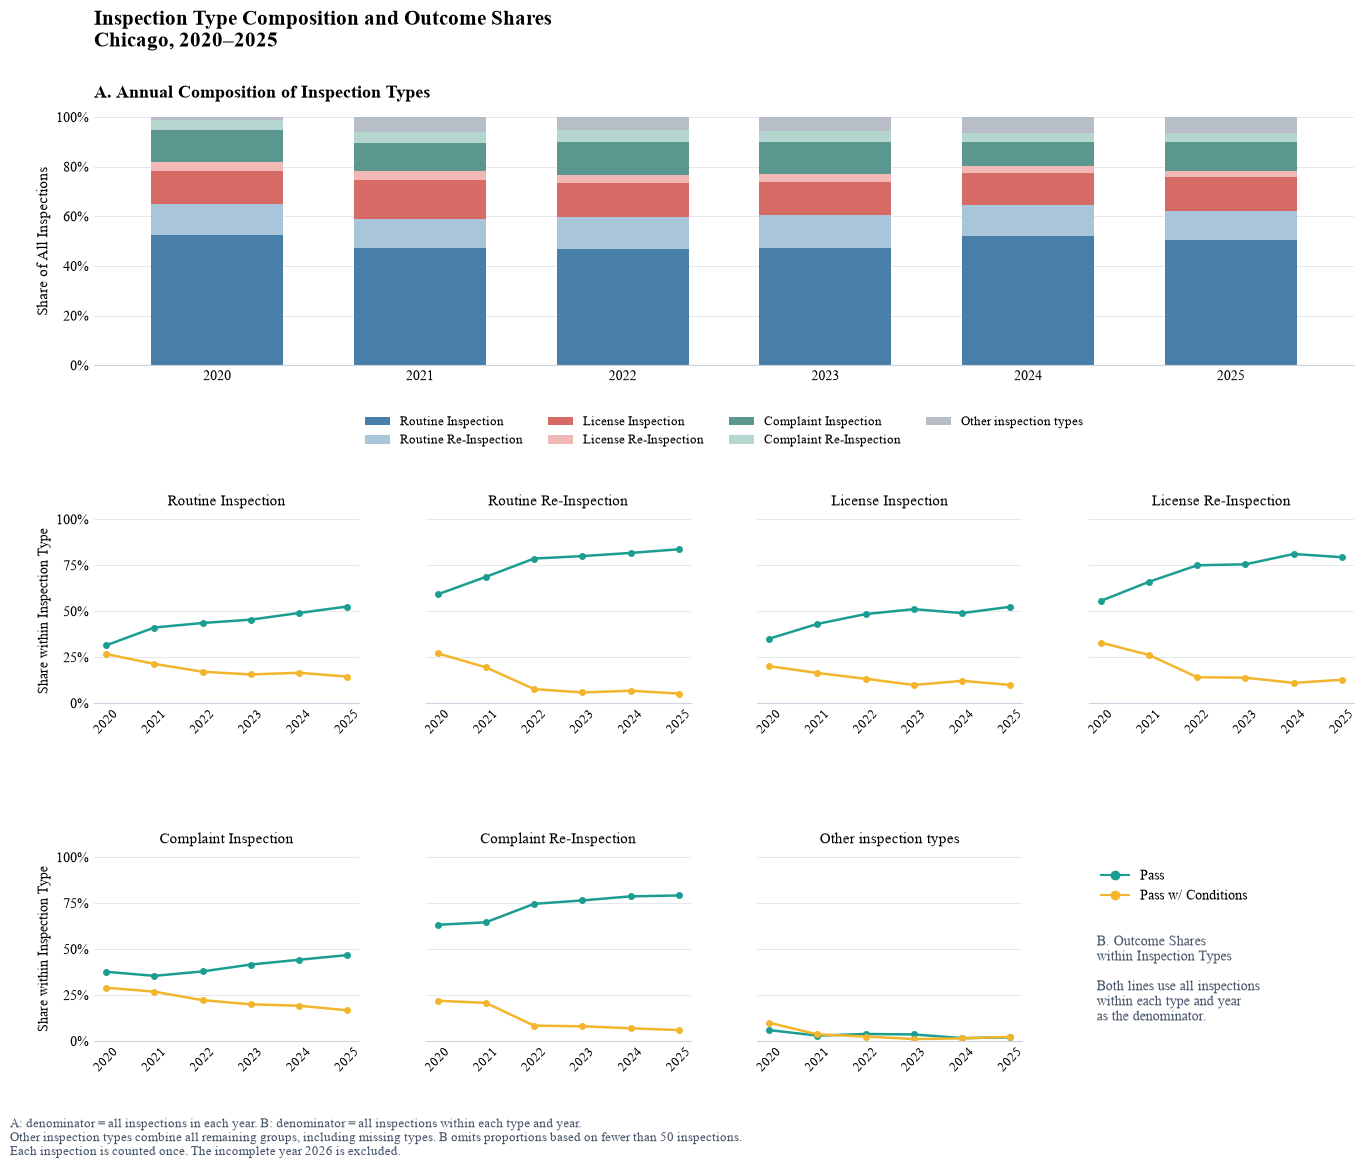

In [8]:
# Use the full inspection table rather than facility-filtered audit_data
annual_data = inspection[
    ['Inspection ID', 'Inspection Date', 'Inspection Group', 'Results']
].copy()

annual_data['Inspection Date'] = pd.to_datetime(
    annual_data['Inspection Date']
)

# Use complete calendar years
annual_data = annual_data[
    (annual_data['Inspection Date'] >= '2020-01-01') &
    (annual_data['Inspection Date'] < '2026-01-01')
].copy()

# Ensure one row per inspection
assert annual_data['Inspection ID'].notna().all()
assert annual_data['Inspection ID'].is_unique

annual_data['Year'] = annual_data['Inspection Date'].dt.year
years = list(range(2020, 2026))

# Retain main purposes and stages; combine remaining types
main_groups = [
    'Routine Inspection',
    'Routine Re-Inspection',
    'License Inspection',
    'License Re-Inspection',
    'Complaint Inspection',
    'Complaint Re-Inspection'
]

group_order = main_groups + ['Other inspection types']

annual_data['Analysis Group'] = annual_data[
    'Inspection Group'
].where(
    annual_data['Inspection Group'].isin(main_groups),
    'Other inspection types'
)

# Figure A: annual inspection-type composition
annual_type_counts = (
    annual_data
    .groupby(['Year', 'Analysis Group'])['Inspection ID']
    .nunique()
    .unstack('Analysis Group', fill_value=0)
    .reindex(index=years, columns=group_order, fill_value=0)
)

annual_total = annual_type_counts.sum(axis=1)

annual_type_shares = annual_type_counts.div(
    annual_total.replace(0, np.nan),
    axis=0
)

# Figure B: outcome shares within each inspection type
annual_data['Is Pass'] = annual_data['Results'].eq('Pass')
annual_data['Is Conditions'] = annual_data[
    'Results'
].eq('Pass w/ Conditions')

annual_group_summary = (
    annual_data
    .groupby(['Year', 'Analysis Group'])
    .agg(
        Inspection_n=('Inspection ID', 'nunique'),
        Pass_n=('Is Pass', 'sum'),
        Conditions_n=('Is Conditions', 'sum')
    )
)

# Complete all year-type combinations
full_index = pd.MultiIndex.from_product(
    [years, group_order],
    names=['Year', 'Analysis Group']
)

annual_group_summary = annual_group_summary.reindex(
    full_index,
    fill_value=0
)

denominator = annual_group_summary['Inspection_n'].replace(0, np.nan)

annual_group_summary['Pass_share'] = (
    annual_group_summary['Pass_n'] / denominator
)

annual_group_summary['Conditions_share'] = (
    annual_group_summary['Conditions_n'] / denominator
)

# Check that type counts sum to the annual inspection total
annual_check = (
    annual_data.groupby('Year')['Inspection ID']
    .nunique()
    .reindex(years, fill_value=0)
)

assert annual_total.equals(annual_check)

# Inspect the validation table; round percentages only for display
# display(annual_type_counts)
# display((annual_type_shares * 100).round(1))

annual_group_display = annual_group_summary.copy()
annual_group_display['Pass_share'] *= 100
annual_group_display['Conditions_share'] *= 100

# display(
#     annual_group_display.rename(columns={
#         'Pass_share': 'Pass_pct',
#         'Conditions_share': 'Conditions_pct'
#     }).round(1)
# )


fig = plt.figure(figsize=(14, 12))

grid = fig.add_gridspec(
    3, 4,
    height_ratios=[1.35, 1, 1],
    hspace=0.75,
    wspace=0.25
)

# Figure A: annual inspection-type composition
ax_a = fig.add_subplot(grid[0, :])

# Use a shared colour family for each purpose; darker for initial inspections
type_colors = [
    '#477FA8', '#A9C5DA',   # Routine
    '#D66B66', '#F2B8B5',   # License
    '#5B968F', '#B5D5CF',   # Complaint
    '#B8BEC7'               # Other
]

bottom = np.zeros(len(years))

for group, color in zip(group_order, type_colors):
    values = annual_type_shares[group].to_numpy()

    ax_a.bar(
        years,
        values,
        bottom=bottom,
        width=0.65,
        color=color,
        label=group
    )

    bottom += values

ax_a.set_title(
    'A. Annual Composition of Inspection Types',
    loc='left',
    fontsize=13,
    fontweight='bold',
    pad=14
)

ax_a.set_ylabel('Share of All Inspections', fontsize=11)
ax_a.set_xticks(years)
ax_a.set_ylim(0, 1)
ax_a.yaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1, decimals=0)
)

ax_a.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.16),
    ncol=4,
    frameon=False,
    fontsize=9
)

# Figure B: outcome shares within each inspection type
min_n = 50

for i, group in enumerate(group_order):
    row = 1 + i // 4
    col = i % 4
    ax = fig.add_subplot(grid[row, col])

    group_data = annual_group_summary.xs(
        group,
        level='Analysis Group'
    ).reindex(years)

    # Leave gaps where yearly samples are too small
    sufficient_n = group_data['Inspection_n'] >= min_n

    pass_share = group_data['Pass_share'].where(sufficient_n)
    conditions_share = group_data['Conditions_share'].where(sufficient_n)

    ax.plot(
        years,
        pass_share,
        color='#1B9E91',
        marker='o',
        markersize=4,
        linewidth=1.8,
        label='Pass'
    )

    ax.plot(
        years,
        conditions_share,
        color='#F2B52B',
        marker='o',
        markersize=4,
        linewidth=1.8,
        label='Pass w/ Conditions'
    )

    ax.set_title(
        fill(group, width=25),
        fontsize=11,
        pad=10
    )

    ax.set_xticks(years)
    ax.tick_params(axis='x', rotation=45, labelsize=9)

    # Use the same vertical scale across panels
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
    ax.yaxis.set_major_formatter(
        mtick.PercentFormatter(xmax=1, decimals=0)
    )

    if col == 0:
        ax.set_ylabel('Share within Inspection Type', fontsize=10)
    else:
        ax.tick_params(axis='y', labelleft=False)

# Use the empty panel for the legend and notes
ax_note = fig.add_subplot(grid[2, 3])
ax_note.axis('off')

ax_note.plot([], [], color='#1B9E91', marker='o', label='Pass')
ax_note.plot(
    [], [],
    color='#F2B52B',
    marker='o',
    label='Pass w/ Conditions'
)

ax_note.legend(
    loc='upper left',
    frameon=False,
    fontsize=10
)

ax_note.text(
    0.03, 0.58,
    'B. Outcome Shares\nwithin Inspection Types\n\n'
    'Both lines use all inspections\n'
    'within each type and year\n'
    'as the denominator.',
    transform=ax_note.transAxes,
    fontsize=10,
    color='#475569',
    va='top'
)

# Apply consistent styling
for ax in fig.axes:
    if ax is ax_note:
        continue

    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#E5E7EB', linewidth=0.7)

    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)

    ax.spines['bottom'].set_color('#CBD5E1')
    ax.tick_params(axis='both', length=0)

fig.suptitle(
    'Inspection Type Composition and Outcome Shares\n'
    'Chicago, 2020–2025',
    x=0.08,
    ha='left',
    fontsize=15,
    fontweight='bold',
    y=0.98
)

fig.text(
    0.02, 0.025,
    'A: denominator = all inspections in each year. '
    'B: denominator = all inspections within each type and year.\n'
    'Other inspection types combine all remaining groups, including missing types. '
    'B omits proportions based on fewer than 50 inspections.\n'
    'Each inspection is counted once. The incomplete year 2026 is excluded.',
    fontsize=9,
    color='#475569'
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.89,
    bottom=0.12
)

plt.show()

Among Conditions inspections with an unambiguous, known subsequent outcome, 37.89% were followed by Pass.


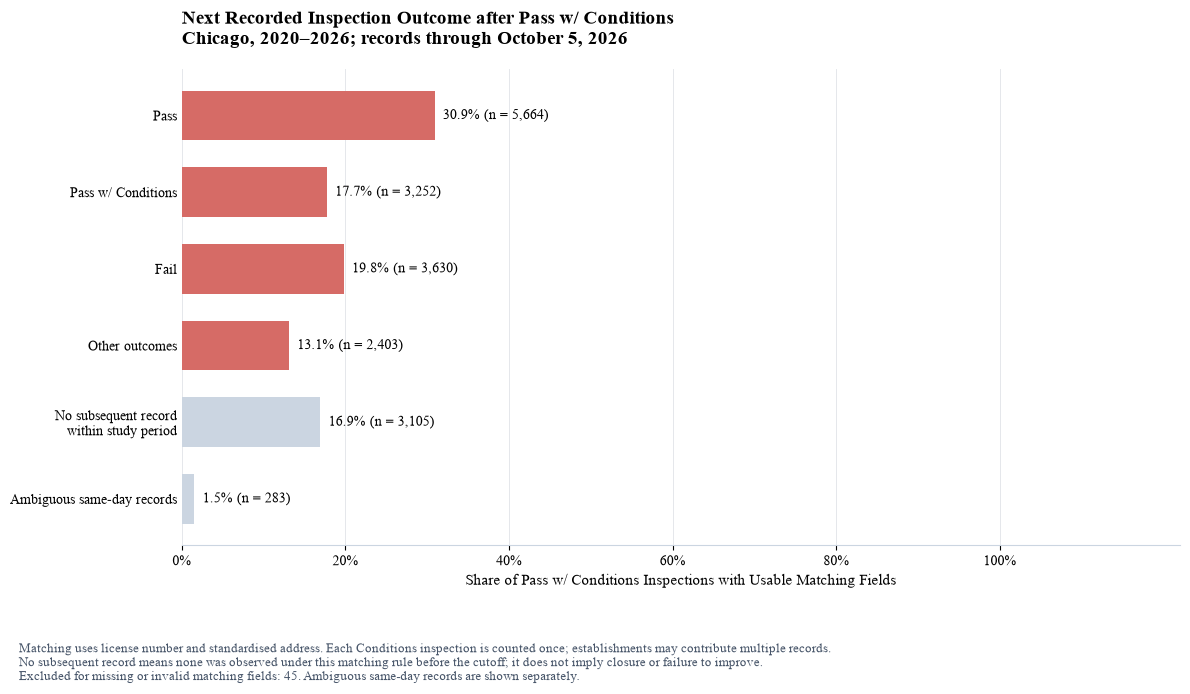

In [9]:
# 1. Prepare data
follow_data = inspection[
    [
        'Inspection ID', 'Inspection Date',
        'License #', 'Address',
        'Latitude', 'Longitude',
        'Results', 'Inspection Group'
    ]
].copy()

follow_data['Inspection Date'] = pd.to_datetime(
    follow_data['Inspection Date']
).dt.normalize()

follow_data = follow_data[
    (follow_data['Inspection Date'] >= '2020-01-01') &
    (follow_data['Inspection Date'] < '2026-10-06')
].copy()

assert follow_data['Inspection ID'].notna().all()
assert follow_data['Inspection ID'].is_unique

# Excel may read license numbers as values such as 123456.0
follow_data['License key'] = (
    follow_data['License #']
    .astype('string')
    .str.strip()
    .str.replace(r'\.0+$', '', regex=True)
)

follow_data['Address key'] = (
    follow_data['Address']
    .astype('string')
    .str.strip()
    .str.upper()
    .str.replace(r'\s+', ' ', regex=True)
)

valid_license = (
    follow_data['License key'].notna() &
    ~follow_data['License key'].str.lower().isin(
        ['', '0', 'nan', 'none', '<na>']
    )
)

valid_address = (
    follow_data['Address key'].notna() &
    ~follow_data['Address key'].str.lower().isin(
        ['', 'nan', 'none', '<na>']
    )
)

valid_key = valid_license & valid_address
is_conditions = follow_data['Results'].eq('Pass w/ Conditions')

# Count Conditions records with missing linkage fields separately
conditions_total_n = int(is_conditions.sum())
unmatched_n = int((is_conditions & ~valid_key).sum())

matched_data = follow_data.loc[valid_key].copy()

keys = ['License key', 'Address key']

# 2. Identify multiple records for the same establishment on the same day
matched_data['Same day n'] = (
    matched_data
    .groupby(keys + ['Inspection Date'])['Inspection ID']
    .transform('size')
)

# Use one row per establishment-day to identify the next inspection date
# Flag multiple same-day records as ambiguous instead of using their outcomes
daily_data = (
    matched_data
    .sort_values(keys + ['Inspection Date', 'Inspection ID'])
    .drop_duplicates(keys + ['Inspection Date'])
    .copy()
)

next_columns = {
    'Inspection ID': 'Next Inspection ID',
    'Inspection Date': 'Next Inspection Date',
    'Results': 'Next Results',
    'Inspection Group': 'Next Inspection Group',
    'Same day n': 'Next Same day n',
    'Latitude': 'Next Latitude',
    'Longitude': 'Next Longitude'
}

# Identify the next inspection among all outcomes before selecting Conditions records
# Do not drop Fail or other outcomes before matching the next inspection
for source, target in next_columns.items():
    daily_data[target] = (
        daily_data.groupby(keys, sort=False)[source].shift(-1)
    )

# 3. Extract Conditions inspections and their follow-up records
conditions_followup = (
    matched_data[
        matched_data['Results'].eq('Pass w/ Conditions')
    ]
    .merge(
        daily_data[
            keys + ['Inspection Date'] + list(next_columns.values())
        ],
        on=keys + ['Inspection Date'],
        how='left',
        validate='many_to_one'
    )
)

conditions_followup['Days to next inspection'] = (
    conditions_followup['Next Inspection Date'] -
    conditions_followup['Inspection Date']
).dt.days

# Initialise as Other before assigning explicit outcome categories
conditions_followup['Follow-up outcome'] = 'Other outcomes'

for result in ['Pass', 'Pass w/ Conditions', 'Fail']:
    conditions_followup.loc[
        conditions_followup['Next Results'].eq(result),
        'Follow-up outcome'
    ] = result

no_next = conditions_followup['Next Inspection Date'].isna()

conditions_followup.loc[
    no_next, 'Follow-up outcome'
] = 'No subsequent record'

# A follow-up date is available but its outcome is missing
missing_result = (
    ~no_next &
    (
        conditions_followup['Next Results'].isna() |
        conditions_followup['Next Results']
        .astype('string').str.strip().eq('').fillna(False)
    )
)

conditions_followup.loc[
    missing_result, 'Follow-up outcome'
] = 'Missing subsequent result'

# Multiple records on either inspection date make the sequence ambiguous
ambiguous = (
    conditions_followup['Same day n'].gt(1) |
    conditions_followup['Next Same day n'].gt(1)
)

conditions_followup.loc[
    ambiguous, 'Follow-up outcome'
] = 'Ambiguous same-day records'

# 4. Summarise
follow_order = [
    'Pass',
    'Pass w/ Conditions',
    'Fail',
    'Other outcomes',
    'No subsequent record',
    'Missing subsequent result',
    'Ambiguous same-day records'
]

follow_counts = (
    conditions_followup['Follow-up outcome']
    .value_counts()
    .reindex(follow_order, fill_value=0)
)

follow_summary = follow_counts.rename('Inspection Count').to_frame()

# Denominator: all Conditions inspections with usable linkage fields
follow_summary['Share'] = (
    follow_summary['Inspection Count'] /
    len(conditions_followup)
    if len(conditions_followup) > 0
    else np.nan
)

assert follow_summary['Inspection Count'].sum() + unmatched_n == conditions_total_n

# display(
#     follow_summary.assign(
#         Share_pct=follow_summary['Share'] * 100
#     ).drop(columns='Share').round(2)
# )

# Validate the linkage range
matching_audit = pd.DataFrame({
    'Measure': [
        'All Pass w/ Conditions inspections',
        'Conditions inspections with usable matching fields',
        'Excluded: missing or invalid matching fields'
    ],
    'Count': [
        conditions_total_n,
        len(conditions_followup),
        unmatched_n
    ]
})

# display(matching_audit)

# Calculate the Pass transition share only among known follow-up outcomes
known_outcomes = [
    'Pass', 'Pass w/ Conditions', 'Fail', 'Other outcomes'
]

known_followup_n = follow_counts.loc[known_outcomes].sum()

if known_followup_n > 0:
    next_pass_rate = follow_counts['Pass'] / known_followup_n

    print(
        'Among Conditions inspections with an unambiguous, '
        f'known subsequent outcome, {next_pass_rate:.2%} '
        'were followed by Pass.'
    )

# Inspect matched records to check license, address, dates and coordinates
# display(
#     conditions_followup[
#         [
#             'Inspection ID', 'License key', 'Address key',
#             'Inspection Date', 'Results',
#             'Next Inspection ID', 'Next Inspection Date',
#             'Next Results', 'Next Inspection Group',
#             'Days to next inspection',
#             'Latitude', 'Longitude',
#             'Next Latitude', 'Next Longitude',
#             'Follow-up outcome'
#         ]
#     ].head(20)
# )






# 5. Plot
# Omit empty ambiguous categories; retain all four explicit outcome categories
show_order = [
    outcome for outcome in follow_order
    if outcome in known_outcomes or follow_counts[outcome] > 0
]

follow_plot = follow_summary.loc[show_order].copy()

if len(conditions_followup) == 0:
    raise ValueError('No Conditions inspections have usable linkage fields. Check the input data.')

label_mapping = {
    'Pass': 'Pass',
    'Pass w/ Conditions': 'Pass w/ Conditions',
    'Fail': 'Fail',
    'Other outcomes': 'Other outcomes',
    'No subsequent record': 'No subsequent record\nwithin study period',
    'Missing subsequent result': 'Missing subsequent result',
    'Ambiguous same-day records': 'Ambiguous same-day records'
}

colors = [
    '#D66B66' if outcome in known_outcomes else '#CBD5E1'
    for outcome in show_order
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    [label_mapping[outcome] for outcome in show_order],
    follow_plot['Share'],
    color=colors,
    height=0.65
)

ax.bar_label(
    bars,
    labels=[
        f'{share:.1%} (n = {int(count):,})'
        for share, count in zip(
            follow_plot['Share'],
            follow_plot['Inspection Count']
        )
    ],
    padding=6,
    fontsize=10
)

ax.invert_yaxis()

# Keep the full percentage range and leave room for labels
ax.set_xlim(0, 1.22)
ax.set_xticks(np.arange(0, 1.01, 0.2))
ax.xaxis.set_major_formatter(
    mtick.PercentFormatter(xmax=1, decimals=0)
)

ax.set_xlabel(
    'Share of Pass w/ Conditions Inspections with Usable Matching Fields',
    fontsize=11
)
ax.set_ylabel('')

ax.set_title(
    'Next Recorded Inspection Outcome after Pass w/ Conditions\n'
    'Chicago, 2020–2026; records through October 5, 2026',
    loc='left',
    fontsize=14,
    fontweight='bold',
    pad=18
)

ax.set_axisbelow(True)
ax.grid(axis='x', color='#E5E7EB', linewidth=0.7)

for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)

ax.spines['bottom'].set_color('#CBD5E1')
ax.tick_params(axis='y', length=0)

fig.text(
    0.02, 0.02,
    'Matching uses license number and standardised address. '
    'Each Conditions inspection is counted once; establishments may contribute multiple records.\n'
    'No subsequent record means none was observed under this matching rule before the cutoff; '
    'it does not imply closure or failure to improve.\n'
    f'Excluded for missing or invalid matching fields: {unmatched_n:,}. '
    'Ambiguous same-day records are shown separately.',
    fontsize=9,
    color='#475569'
)

plt.tight_layout(rect=[0, 0.13, 1, 1]) #type: ignore
plt.show()

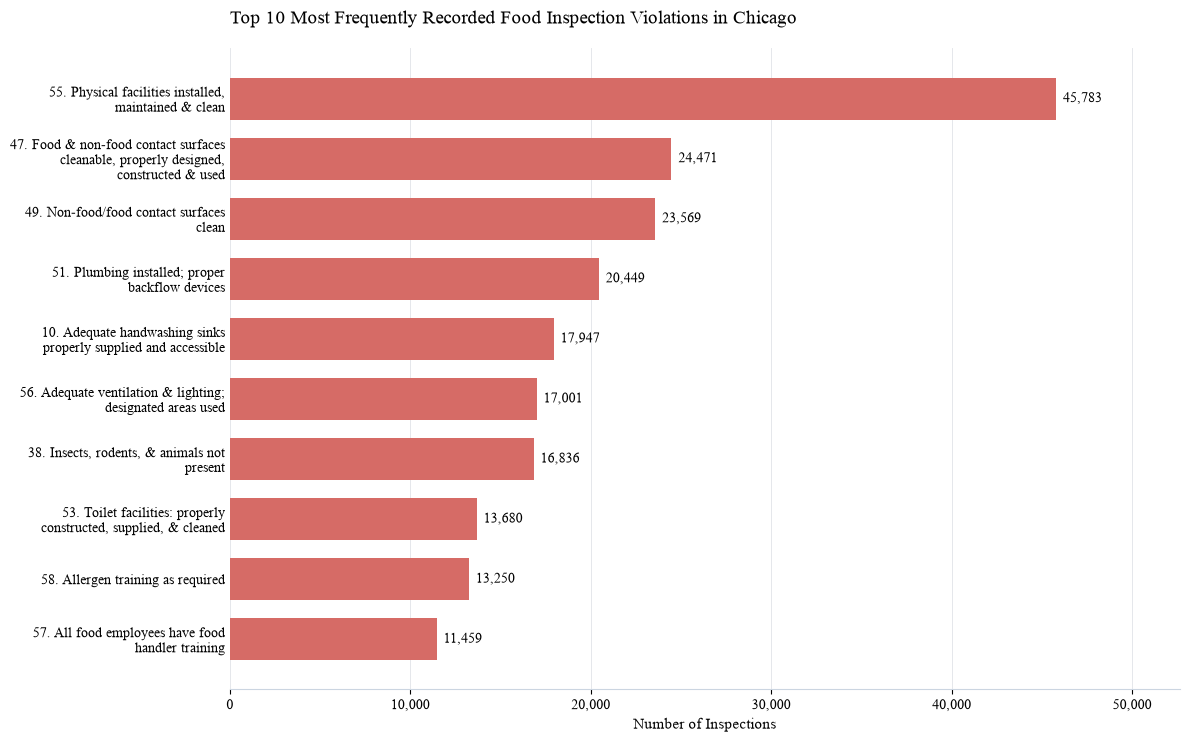

In [10]:
p9_violation_codes = violation_codes.copy()
p9_violation_codes = p9_violation_codes.drop_duplicates()

# Deduplicate before counting
p9_code_frequency = p9_violation_codes.groupby('Violation Code').agg(cnt = ('Inspection ID', 'count')).reset_index().rename(columns = {'cnt': 'Inspection Count'})

# Use the most frequent description for each violation code
p9_code_name = violation.groupby(['Violation Code', 'Violation Description']).size().rename('Name Frequency').reset_index().sort_values('Name Frequency', ascending = False).drop_duplicates('Violation Code')[['Violation Code', 'Violation Description']]
p9_code_name.head()

p9_code_summary = pd.merge(p9_code_frequency, p9_code_name, how = 'left', on = 'Violation Code')

p9_top10_violation = p9_code_summary.sort_values('Inspection Count', ascending = False).head(10).sort_values('Inspection Count')
p9_top10_violation['Label'] = p9_top10_violation.apply(lambda x: fill(f"{int(x['Violation Code'])}. " + f"{x['Violation Description'].lower().capitalize()}", width = 36), axis = 1)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(p9_top10_violation['Label'], p9_top10_violation['Inspection Count'], color='#D66B66', height=0.7)
ax.bar_label(bars, labels=[f'{count:,}'for count in p9_top10_violation['Inspection Count']], padding = 5, fontsize = 10)


ax.set_xlim(0, p9_top10_violation['Inspection Count'].max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:,.0f}')) # type: ignore


ax.set_xlabel('Number of Inspections', fontsize=11)
ax.set_ylabel('')
ax.set_title('Top 10 Most Frequently Recorded Food Inspection Violations in Chicago', loc = 'left', fontsize = 14, pad = 18)


ax.set_axisbelow(True)
ax.grid(axis = 'x', color = '#E5E7EB', linewidth = 0.7)


for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#CBD5E1')
ax.tick_params(axis = 'y', length=0)



plt.tight_layout(rect = [0, 0.06, 1, 1]) # type: ignore
plt.show()

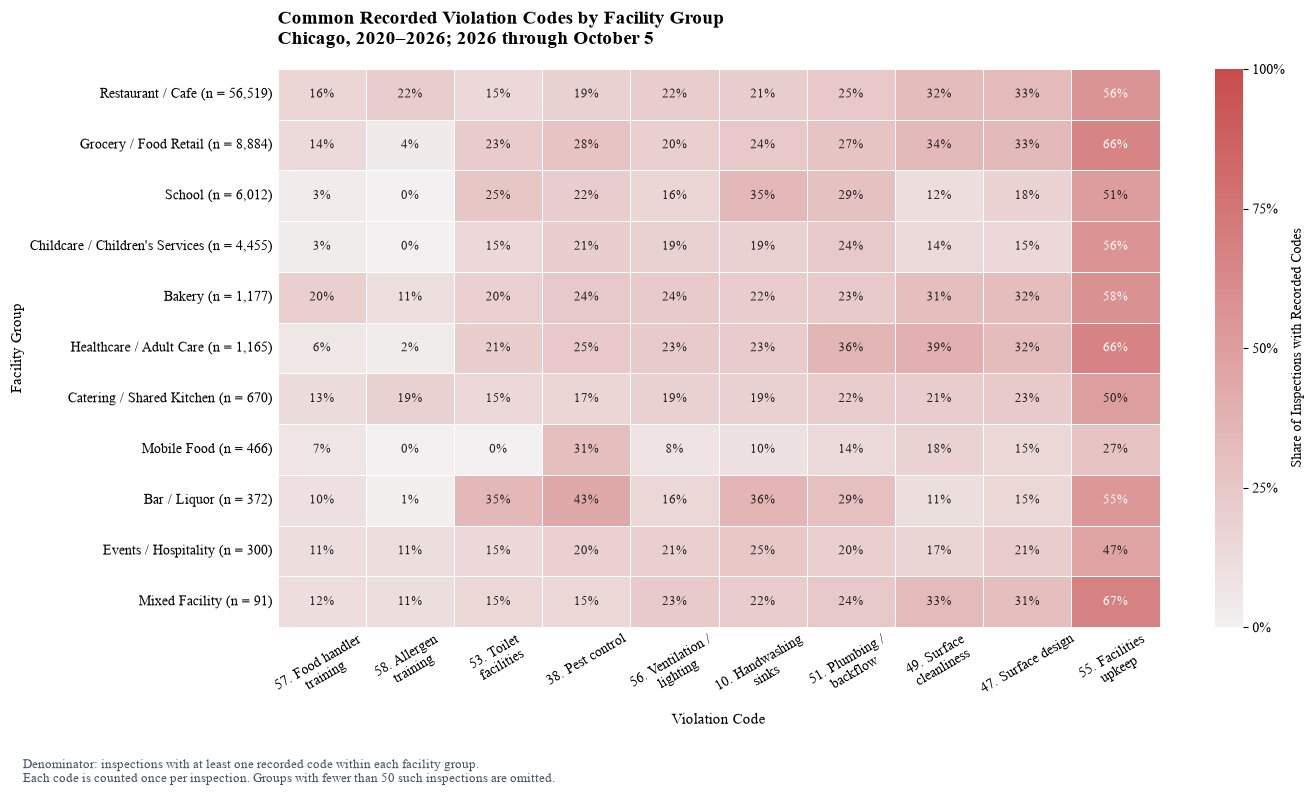

In [11]:
p11_codes = violation_codes.drop_duplicates()

p11_inspection = inspection[['Inspection ID', 'Facility Group']]
p11_inspection = p11_inspection[~p11_inspection['Facility Group'].isin(['Unknown', 'Unclassified', 'Other'])]

p11_data = pd.merge(p11_inspection, p11_codes, how = 'inner', on = 'Inspection ID')

# Count distinct inspection-code pairs within each group
p11_group_violation_code_num = p11_data.groupby('Facility Group')['Inspection ID'].nunique()

# Use the top 10 codes and order from P9
p11_top_codes_list = p9_top10_violation['Violation Code'].to_list()

# Count inspections recording each code within each group
p11_counts = p11_data[p11_data['Violation Code'].isin(p11_top_codes_list)].groupby(['Facility Group', 'Violation Code'])['Inspection ID'].nunique().unstack('Violation Code', fill_value = 0).reindex(index = p11_group_violation_code_num.index, columns = p11_top_codes_list, fill_value = 0)

# Calculate proportions
p11_rates = p11_counts.div(p11_group_violation_code_num, axis=0)


# Show facility groups with at least 50 inspections containing recorded codes
p11_group_order = p11_group_violation_code_num[p11_group_violation_code_num >= 50].sort_values(ascending = False).index
p11_rates = p11_rates.loc[p11_group_order]



p11_short_names = {
    55: 'Facilities upkeep',
    47: 'Surface design',
    49: 'Surface cleanliness',
    51: 'Plumbing / backflow',
    10: 'Handwashing sinks',
    56: 'Ventilation / lighting',
    38: 'Pest control',
    53: 'Toilet facilities',
    58: 'Allergen training',
    57: 'Food handler training'
}

# Set axis labels
p11_xlabels = [fill(f'{int(code)}. {p11_short_names[int(code)]}', width = 18) for code in p11_top_codes_list]
p11_ylabels = [f'{group} (n = {p11_group_violation_code_num.loc[group]:,})' for group in p11_rates.index]
# Annotate percentages
p11_annotations = p11_rates.map(lambda value: f'{value:.0%}')


fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(p11_rates, ax = ax,
    cmap = sns.light_palette('#C94C4C', as_cmap=True),
    vmin = 0, vmax = 1,
    annot = p11_annotations,
    fmt = '',
    annot_kws = {'fontsize': 9},
    linewidths = 0.6,
    linecolor = 'white',
    xticklabels = p11_xlabels,
    yticklabels = p11_ylabels,
    cbar_kws={'label': 'Share of Inspections with Recorded Codes', 'ticks': [0, 0.25, 0.5, 0.75, 1]})

# Set the colour scale
colorbar = ax.collections[0].colorbar
colorbar.set_ticklabels(['0%', '25%', '50%', '75%', '100%']) # type: ignore


ax.set_title(
    'Common Recorded Violation Codes by Facility Group\n'
    'Chicago, 2020–2026; 2026 through October 5',
    loc = 'left',
    fontsize = 14,
    fontweight = 'bold',
    pad = 18
)


ax.set_xlabel('Violation Code', fontsize = 11)
ax.set_ylabel('Facility Group', fontsize = 11)
ax.tick_params(axis = 'x', rotation = 30, length = 0)
ax.tick_params(axis = 'y', rotation = 0, length = 0)

fig.text(
    0.02, 0.015,
    'Denominator: inspections with at least one recorded code within each facility group.\n'
    'Each code is counted once per inspection. Groups with fewer than 50 such inspections are omitted.',
    fontsize = 9,
    color = '#475569'
)

plt.tight_layout(rect = [0, 0.065, 1, 1]) # type: ignore
plt.show()

Clustering units: 11 facility groups
Clustering features: 10 violation-code proportions


Violation Code,57,58,53,38,56,10,51,49,47,55
Facility Group,,,,,,,,,,
Restaurant / Cafe,16.4,22.1,15.2,19.3,22.0,20.9,24.9,31.7,32.9,56.2
Grocery / Food Retail,14.5,4.1,23.0,27.6,20.1,24.2,26.7,33.7,33.2,65.8
School,3.3,0.2,25.5,21.9,16.4,34.5,28.6,12.0,17.8,50.6
Childcare / Children's Services,2.9,0.4,14.8,20.9,19.1,18.9,24.2,14.4,14.5,56.4
Bakery,20.2,10.6,19.8,23.9,23.5,21.8,23.3,30.8,31.5,57.9
Healthcare / Adult Care,5.8,2.4,20.9,24.8,23.2,22.7,35.8,38.9,31.9,66.3
Catering / Shared Kitchen,12.8,19.0,14.8,17.2,19.4,19.0,22.4,21.2,23.3,50.1
Mobile Food,6.7,0.4,0.2,30.7,8.2,9.7,14.2,17.6,15.5,27.5
Bar / Liquor,9.9,0.8,34.7,43.3,15.6,36.0,29.3,11.3,15.3,54.6


,Step,Group A,Group B,Merge height,Number of facility groups
0,1,Events / Hospitality,Catering / Shared Kitchen,0.120,2
1,2,Restaurant / Cafe,Bakery,0.141,2
2,3,Healthcare / Adult Care,Grocery / Food Retail,0.146,2
3,4,Restaurant / Cafe + Bakery,Mixed Facility,0.170,3
4,5,School,Childcare / Children's Services,0.209,2
5,6,Healthcare / Adult Care + Grocery / Food Retail,Restaurant / Cafe + Bakery + Mixed Facility,0.288,5
6,7,School + Childcare / Children's Services,Events / Hospitality + Catering / Shared Kitchen,0.312,4
7,8,Bar / Liquor,School + Childcare / Children's Services + Events / Hospitality + Catering / Shared Kitchen,0.424,5
8,9,Bar / Liquor + School + Childcare / Children's Services + Events / Hospitality + Catering / Shared Kitchen,Mobile Food,0.518,6
9,10,Healthcare / Adult Care + Grocery / Food Retail + Restaurant / Cafe + Bakery + Mixed Facility,Bar / Liquor + School + Childcare / Children's Services + Events / Hospitality + Catering / Shared Kitchen + Mobile Food,0.689,11


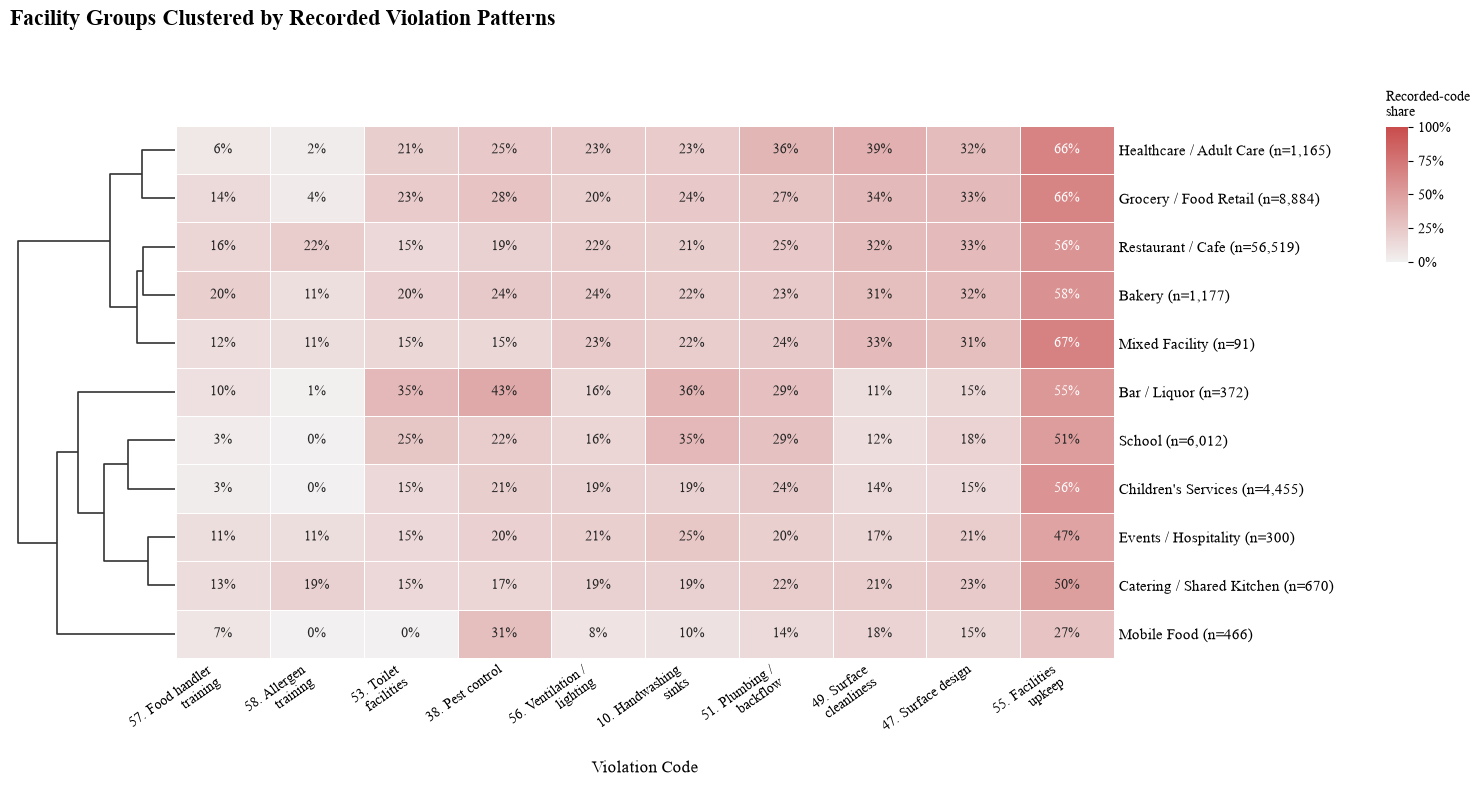

,Number of clusters,Silhouette score,Smallest cluster,Singleton clusters
0,2,0.285,5,0
1,3,0.284,1,1
2,4,0.254,1,2
3,5,0.236,1,2


Initial solution based on silhouette score: 2 clusters


,Facility Group,Cluster,Recorded inspections
0,Healthcare / Adult Care,Cluster 1,1165
1,Grocery / Food Retail,Cluster 1,8884
2,Restaurant / Cafe,Cluster 1,56519
3,Bakery,Cluster 1,1177
4,Mixed Facility,Cluster 1,91
5,Bar / Liquor,Cluster 2,372
6,School,Cluster 2,6012
7,Childcare / Children's Services,Cluster 2,4455
8,Events / Hospitality,Cluster 2,300
9,Catering / Shared Kitchen,Cluster 2,670


Violation Code,57,58,53,38,56,10,51,49,47,55
Cluster,,,,,,,,,,
Cluster 1,13.8,10.0,18.9,22.2,22.4,22.3,27.0,33.6,32.1,62.6
Cluster 2,7.8,5.4,17.4,25.6,16.6,23.9,23.1,15.6,17.9,47.7


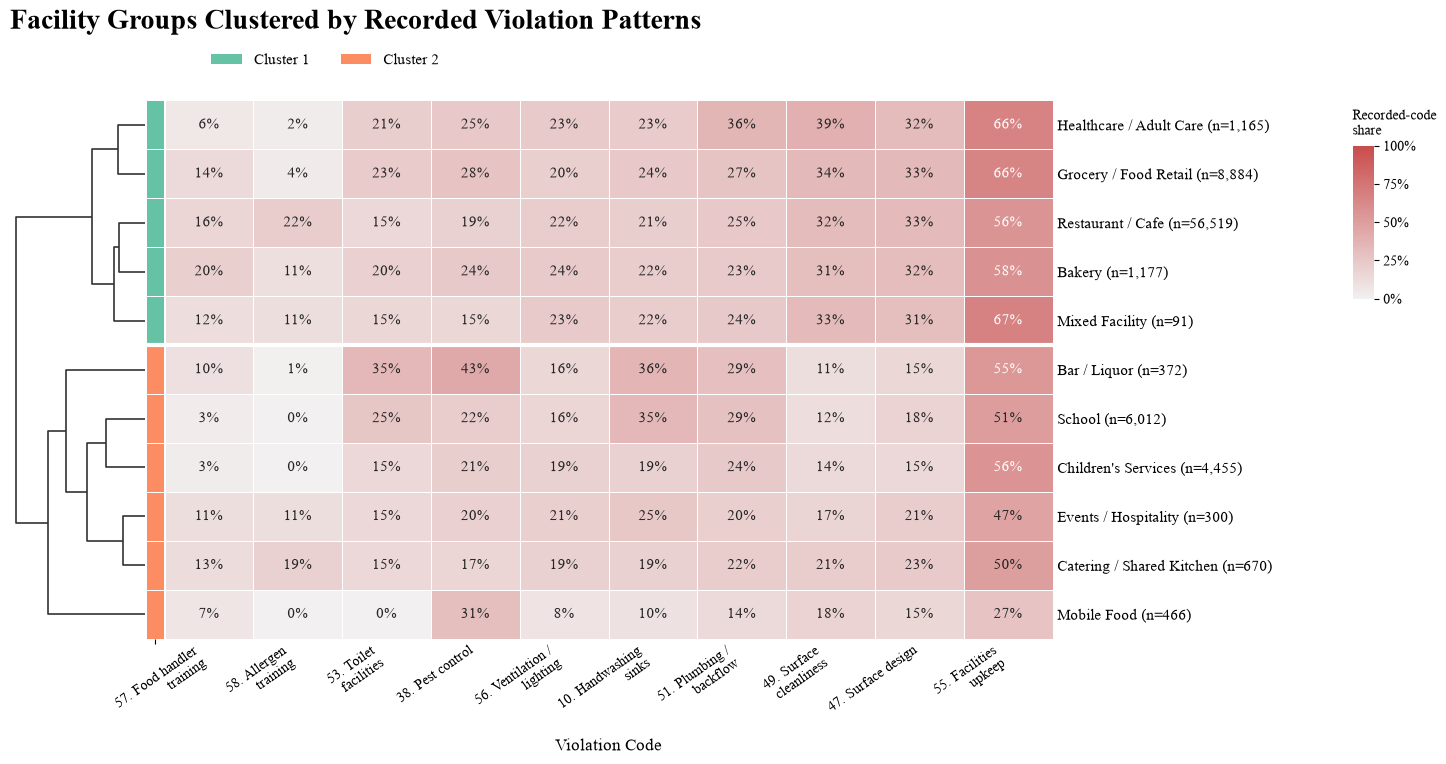

In [12]:
# Continue P11 with cluster analysis
# Use the top 10 violation-code proportions as clustering features
p11_cluster_rates = p11_rates.copy().astype(float)

# Validate inputs
assert p11_cluster_rates.index.is_unique
assert p11_cluster_rates.columns.is_unique
assert not p11_cluster_rates.isna().any().any()
assert np.isfinite(p11_cluster_rates.to_numpy()).all()
assert p11_cluster_rates.ge(0).all().all()
assert p11_cluster_rates.le(1).all().all()

p11_sample_n = p11_group_violation_code_num.reindex(
    p11_cluster_rates.index
)
assert p11_sample_n.ge(50).all()

print(
    f"Clustering units: {p11_cluster_rates.shape[0]} facility groups\n"
    f"Clustering features: {p11_cluster_rates.shape[1]} violation-code proportions"
)

# Display percentages; retain 0-1 proportions as clustering inputs
display((p11_cluster_rates * 100).round(1))

# Calculate Euclidean distances between facility groups
p11_distances = pdist(
    p11_cluster_rates.to_numpy(),
    metric="euclidean"
)

# Perform Ward hierarchical clustering
p11_linkage = linkage(
    p11_distances,
    method="ward",
    optimal_ordering=True
)


p11_n = len(p11_cluster_rates)

# Store the facility groups represented by each node
p11_members = {
    i: [name]
    for i, name in enumerate(p11_cluster_rates.index)
}

p11_merge_rows = []

for step, (left, right, height, count) in enumerate(p11_linkage):
    left = int(left)
    right = int(right)

    left_members = p11_members[left]
    right_members = p11_members[right]

    p11_merge_rows.append({
        "Step": step + 1,
        "Group A": " + ".join(left_members),
        "Group B": " + ".join(right_members),
        "Merge height": height,
        "Number of facility groups": int(count)
    })

    p11_members[p11_n + step] = left_members + right_members

p11_merge_table = pd.DataFrame(p11_merge_rows)

display(
    p11_merge_table.style.format({
        "Merge height": "{:.3f}"
    })
)



p11_short_names = {
    55: "Facilities upkeep",
    47: "Surface design",
    49: "Surface cleanliness",
    51: "Plumbing / backflow",
    10: "Handwashing sinks",
    56: "Ventilation / lighting",
    38: "Pest control",
    53: "Toilet facilities",
    58: "Allergen training",
    57: "Food handler training"
}

p11_column_labels = [
    fill(
        f"{int(code)}. {p11_short_names[int(code)]}",
        width=18
    )
    for code in p11_cluster_rates.columns
]

# Set fonts locally without affecting other figures
with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"]
}):
    p11_cluster_plot = sns.clustermap(
        p11_cluster_rates,

        # Use the precomputed clustering result
        row_linkage=p11_linkage,
        row_cluster=True,
        col_cluster=False,

        # Use raw proportions without row or column standardisation
        z_score=None,
        standard_scale=None,

        cmap=sns.light_palette("#C94C4C", as_cmap=True),
        vmin=0,
        vmax=1,

        annot=True,
        fmt=".0%",
        annot_kws={"fontsize": 10},

        linewidths=0.6,
        linecolor="white",

        xticklabels=p11_column_labels,
        yticklabels=True,

        figsize=(16, 9),
        dendrogram_ratio=(0.15, 0.03),
        tree_kws={"linewidths": 1.2},

        cbar_kws={
            "ticks": [0, 0.25, 0.5, 0.75, 1]
        }
    )

    # Label rows in the actual clustered order
    p11_leaf_order = (
        p11_cluster_plot.dendrogram_row.reordered_ind # type: ignore
    )
    p11_ordered_groups = (
        p11_cluster_rates.index[p11_leaf_order]
    )

    p11_row_labels = []
    for group in p11_ordered_groups:
        short_group = group.replace(
            "Childcare / Children's Services",
            "Children's Services"
        )
        p11_row_labels.append(
            f"{short_group} "
            f"(n={int(p11_sample_n.loc[group]):,})"
        )

    ax = p11_cluster_plot.ax_heatmap

    ax.set_yticklabels(
        p11_row_labels,
        rotation=0,
        fontsize=11
    )
    ax.set_xticklabels(
        p11_column_labels,
        rotation=35,
        ha="right",
        fontsize=10
    )

    ax.set_xlabel("Violation Code", fontsize=12, labelpad=12)
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)

    # Leave room for facility labels and notes
    p11_cluster_plot.fig.subplots_adjust(
        left=0.03,
        right=0.72,
        top=0.86,
        bottom=0.25
    )

    # Position the colour bar separately to avoid overlap
    p11_cluster_plot.ax_cbar.set_position( # type: ignore
        [0.89, 0.69, 0.014, 0.15] # type: ignore
    )
    p11_cluster_plot.ax_cbar.yaxis.set_major_formatter( # type: ignore
        PercentFormatter(xmax=1, decimals=0)
    )
    p11_cluster_plot.ax_cbar.set_title( # type: ignore
        "Recorded-code\nshare",
        fontsize=10,
        loc="left",
        pad=8
    )

    p11_cluster_plot.fig.suptitle(
        "Facility Groups Clustered by Recorded Violation Patterns",
        x=0.03,
        y=0.97,
        ha="left",
        fontsize=16,
        fontweight="bold"
    )

    plt.show()


p11_scores = []
p11_candidate_labels = {}

for k in range(2, 6):
    labels = cut_tree(
        p11_linkage,
        n_clusters=k
    ).ravel()

    score = silhouette_score(
        p11_cluster_rates.to_numpy(),
        labels,
        metric="euclidean"
    )

    group_sizes = pd.Series(labels).value_counts()

    p11_scores.append({
        "Number of clusters": k,
        "Silhouette score": score,
        "Smallest cluster": group_sizes.min(),
        "Singleton clusters": (group_sizes == 1).sum()
    })

    p11_candidate_labels[k] = labels

p11_score_table = pd.DataFrame(p11_scores)

display(
    p11_score_table.style.format({
        "Silhouette score": "{:.3f}"
    })
)

# Choose the candidate cluster count with the highest silhouette score
p11_k = int(
    p11_score_table.loc[
        p11_score_table["Silhouette score"].idxmax(),
        "Number of clusters"
    ]
)

print(f"Initial solution based on silhouette score: {p11_k} clusters")

# Number clusters in top-to-bottom dendrogram order
p11_raw_labels = p11_candidate_labels[p11_k]
p11_leaf_order = leaves_list(p11_linkage)

p11_cluster_sequence = list(
    dict.fromkeys(p11_raw_labels[p11_leaf_order])
)

p11_cluster_mapping = {
    old: f"Cluster {i + 1}"
    for i, old in enumerate(p11_cluster_sequence)
}

p11_clusters = pd.Series(
    [p11_cluster_mapping[label] for label in p11_raw_labels],
    index=p11_cluster_rates.index,
    name="Cluster"
)

# Display cluster members
p11_membership = pd.DataFrame({
    "Facility Group": p11_cluster_rates.index,
    "Cluster": p11_clusters.to_numpy(),
    "Recorded inspections": p11_sample_n.to_numpy()
})

display(
    p11_membership.iloc[p11_leaf_order].reset_index(drop=True)
)

# Calculate cluster means with equal weights for facility groups
# These describe cluster profiles, not pooled inspection-level proportions
p11_cluster_profiles = (
    p11_cluster_rates
    .groupby(p11_clusters)
    .mean()
)

display((p11_cluster_profiles * 100).round(1))


p11_cluster_names = [
    f"Cluster {i + 1}" for i in range(p11_k)
]

# Use cluster-strip colours distinct from the heatmap scale
p11_cluster_palette = dict(zip(
    p11_cluster_names,
    sns.color_palette("Set2", n_colors=p11_k)
))

p11_row_colors = p11_clusters.map(p11_cluster_palette)
p11_row_colors.name = ""

p11_column_labels = [
    fill(
        f"{int(code)}. {p11_short_names[int(code)]}",
        width=18
    )
    for code in p11_cluster_rates.columns
]

with plt.rc_context({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"]
}):
    p11_cluster_plot = sns.clustermap(
        p11_cluster_rates,
        row_linkage=p11_linkage,
        row_cluster=True,
        col_cluster=False,

        row_colors=p11_row_colors,

        cmap=sns.light_palette("#C94C4C", as_cmap=True),
        vmin=0,
        vmax=1,

        annot=True,
        fmt=".0%",
        annot_kws={"fontsize": 11},

        linewidths=0.6,
        linecolor="white",

        xticklabels=p11_column_labels,
        yticklabels=True,

        figsize=(15, 8.5),
        dendrogram_ratio=(0.13, 0.01),
        colors_ratio=0.018,
        tree_kws={"linewidths": 1.2},

        cbar_kws={
            "ticks": [0, 0.25, 0.5, 0.75, 1]
        }
    )

    ax = p11_cluster_plot.ax_heatmap

    order = p11_cluster_plot.dendrogram_row.reordered_ind
    ordered_groups = p11_cluster_rates.index[order]
    ordered_clusters = p11_clusters.iloc[order].to_numpy()

    row_labels = [
        f"{group.replace('Childcare / Children’s Services', 'Children’s Services').replace(chr(39), chr(39))}"
        for group in ordered_groups
    ]

    # Shorten names and append sample sizes
    row_labels = [
        (
            group.replace(
                "Childcare / Children's Services",
                "Children's Services"
            )
            + f" (n={int(p11_sample_n.loc[group]):,})"
        )
        for group in ordered_groups
    ]

    ax.set_yticklabels(row_labels, rotation=0, fontsize=11)
    ax.set_xticklabels(
        p11_column_labels,
        rotation=35,
        ha="right",
        fontsize=10
    )

    ax.set_xlabel("Violation Code", fontsize=12, labelpad=10)
    ax.set_ylabel("")
    ax.tick_params(axis="both", length=0)

    # Add white separators at cluster boundaries
    boundaries = (
        np.flatnonzero(
            ordered_clusters[1:] != ordered_clusters[:-1]
        ) + 1
    )

    for boundary in boundaries:
        ax.axhline(
            boundary,
            color="white",
            linewidth=3
        )
        p11_cluster_plot.ax_row_colors.axhline(
            boundary,
            color="white",
            linewidth=3
        )

    p11_cluster_plot.fig.subplots_adjust(
        left=0.025,
        right=0.72,
        top=0.88,
        bottom=0.24
    )

    p11_cluster_plot.ax_cbar.set_position(
        [0.92, 0.64, 0.014, 0.18]
    )
    p11_cluster_plot.ax_cbar.yaxis.set_major_formatter(
        PercentFormatter(xmax=1, decimals=0)
    )
    p11_cluster_plot.ax_cbar.set_title(
        "Recorded-code\nshare",
        fontsize=10,
        loc="left",
        pad=8
    )

    p11_cluster_plot.fig.suptitle(
        "Facility Groups Clustered by Recorded Violation Patterns",
        x=0.025,
        y=0.98,
        ha="left",
        fontsize=20,
        fontweight="bold"
    )

    # Cluster legend
    handles = [
        Patch(
            facecolor=p11_cluster_palette[name],
            label=name
        )
        for name in p11_cluster_names
    ]

    p11_cluster_plot.fig.legend(
        handles=handles,
        loc="upper left",
        bbox_to_anchor=(0.15, 0.945),
        ncol=p11_k,
        frameon=False,
        fontsize=11
    )

    plt.show()


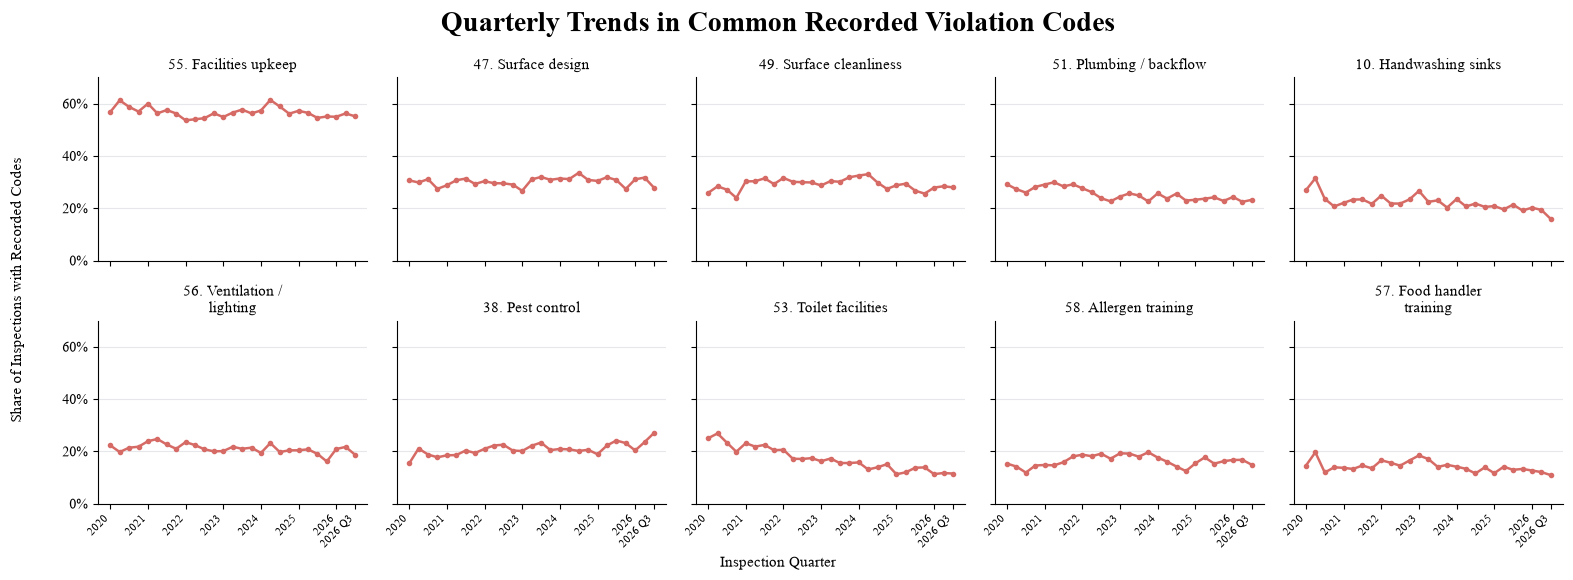

In [13]:
# Retain data through 2026 Q3; exclude the incomplete fourth quarter
p12_inspections = inspection[['Inspection ID', 'Inspection Date']].drop_duplicates('Inspection ID').copy()
p12_inspections['Inspection Date'] = pd.to_datetime( p12_inspections['Inspection Date'])
p12_inspections = p12_inspections[(p12_inspections['Inspection Date'] >= '2020-01-01') & (p12_inspections['Inspection Date'] < '2026-10-01')].copy()
p12_inspections['Quarter'] = (p12_inspections['Inspection Date'].dt.to_period('Q'))

# Convert violation-code types
p12_codes = violation_codes[['Inspection ID', 'Violation Code']].drop_duplicates().copy()
p12_codes['Violation Code'] = pd.to_numeric(p12_codes['Violation Code']).astype('Int64')

# Merge tables
p12_data = pd.merge(p12_inspections, p12_codes, how = 'inner', on = 'Inspection ID')

# Count distinct inspections with at least one recorded code per quarter (denominator)
p12_quarters = pd.period_range('2020Q1', '2026Q3', freq='Q')
p12_quarters_n = p12_data.groupby('Quarter')['Inspection ID'].nunique().reindex(p12_quarters)


# Order codes by P9 recorded frequency
p12_top10 = p9_top10_violation[['Violation Code', 'Inspection Count']].sort_values(['Inspection Count', 'Violation Code'], ascending = [False, True])
p12_top_codes = pd.to_numeric(p12_top10['Violation Code']).astype('Int64').tolist()

# Count distinct inspections recording each code per quarter (numerator)
p12_counts = p12_data[p12_data['Violation Code'].isin(p12_top_codes)].groupby(['Quarter', 'Violation Code'])['Inspection ID'].nunique().unstack('Violation Code', fill_value=0).reindex(index = p12_quarters, columns = p12_top_codes, fill_value = 0)

# Calculate proportions
p12_rates = p12_counts.div(p12_quarters_n, axis = 0)


# Draw the figure
p12_short_names = {
    55: 'Facilities upkeep',
    47: 'Surface design',
    49: 'Surface cleanliness',
    51: 'Plumbing / backflow',
    10: 'Handwashing sinks',
    56: 'Ventilation / lighting',
    38: 'Pest control',
    53: 'Toilet facilities',
    58: 'Allergen training',
    57: 'Food handler training'
}

fig, axes = plt.subplots(2, 5, figsize = (16, 8), sharex = True, sharey = True)

p12_x = list(range(len(p12_quarters)))

# Add a tick for each first quarter and for 2026 Q3
p12_tick_positions = [i for i, quarter in enumerate(p12_quarters) if quarter.quarter == 1]
p12_tick_positions.append(len(p12_quarters) - 1)

p12_tick_labels = [str(p12_quarters[i].year) if p12_quarters[i].quarter == 1 else '2026 Q3' for i in p12_tick_positions]


plt.rcParams['font.family'] = 'Times New Roman'

for ax, code in zip(axes.flat, p12_top_codes):
    ax.plot(p12_x,  p12_rates[code], color = '#D66B66', linewidth = 1.8, marker = 'o',markersize = 3)

    ax.set_title(fill(f'{code}. {p12_short_names[code]}', width = 24), fontsize = 11)

    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax = 1, decimals = 0))

    ax.set_xticks(p12_tick_positions)
    ax.set_xticklabels(p12_tick_labels, rotation = 45, ha = 'right',fontsize = 8)

    ax.grid(axis = 'y', color  ='#E5E7EB')
    ax.set_axisbelow(True)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

fig.suptitle(
    'Quarterly Trends in Common Recorded Violation Codes\n',
    fontsize = 20,
    fontweight = 'bold',
    y = 0.85
)

fig.supxlabel('Inspection Quarter', fontsize = 11, y = 0.15)
fig.supylabel(
    'Share of Inspections with Recorded Codes',
    fontsize=11
)


ax.set_ylim(0, 0.7)
ax.set_yticks([0, 0.2, 0.4, 0.6])

plt.tight_layout(rect=[0.025, 0.12, 1, 0.90]) # type: ignore
plt.show()

Sensitivity analysis


In [14]:
audit_data = inspection.copy()

# Ensure one row per inspection to avoid double counting
assert audit_data['Inspection ID'].notna().all()
assert audit_data['Inspection ID'].is_unique

excluded_groups = ['Unknown', 'Unclassified', 'Other']

audit_data = audit_data[audit_data['Facility Group'].notna() & ~audit_data['Facility Group'].isin(excluded_groups)].copy()

# Inspect the inspection-type composition of each facility group
audit_mix_counts = pd.crosstab(audit_data['Facility Group'], audit_data['Inspection Group'].fillna('Missing'))

audit_mix_pct = audit_mix_counts.div(audit_mix_counts.sum(axis=1), axis=0).mul(100).round(1)
audit_mix_pct['sum'] = audit_mix_pct['Assessment'] + audit_mix_pct['COVID Complaint'] + audit_mix_pct['Complaint Inspection'] + audit_mix_pct['Complaint Re-Inspection'] + audit_mix_pct['Consultation'] + audit_mix_pct['Inspection Not Completed'] + audit_mix_pct['License Inspection'] + audit_mix_pct['License Re-Inspection'] + audit_mix_pct['Non-Inspection'] + audit_mix_pct['Recent Inspection'] + audit_mix_pct['Routine Re-Inspection'] + audit_mix_pct['Suspected Food Poisoning'] + audit_mix_pct['Suspected Food Poisoning Re-Inspection'] + audit_mix_pct['Routine Inspection']

display(audit_mix_pct)



audit_completed = audit_data[audit_data['Results'].isin(['Pass', 'Pass w/ Conditions', 'Fail'])].copy()

audit_completed['Failed'] = audit_completed['Results'].eq('Fail')

# All inspection types
audit_all = audit_completed.groupby('Facility Group').agg(All_n = ('Inspection ID', 'nunique'), All_failed = ('Failed', 'sum'))


audit_all['All_rate'] = audit_all['All_failed'] / audit_all['All_n']

# Routine initial inspections only, excluding Routine Re-Inspection
audit_routine = audit_completed[audit_completed['Inspection Group'].eq('Routine Inspection')].groupby('Facility Group').agg(Routine_n = ('Inspection ID', 'nunique'), Routine_failed = ('Failed', 'sum'))


audit_routine['Routine_rate'] = audit_routine['Routine_failed'] / audit_routine['Routine_n']

audit_comparison = audit_all.join(audit_routine)

# Convert to percentages and calculate percentage-point differences
audit_comparison['All_rate_pct'] = audit_comparison['All_rate'] * 100


audit_comparison['Routine_rate_pct'] = audit_comparison['Routine_rate'] * 100

audit_comparison['Difference_pp'] = audit_comparison['Routine_rate_pct'] - audit_comparison['All_rate_pct']


audit_comparison = audit_comparison.sort_values('All_rate_pct', ascending = False)

display(audit_comparison[['All_n', 'Routine_n', 'All_rate_pct', 'Routine_rate_pct', 'Difference_pp']].round(1))

Inspection Group,Assessment,COVID Complaint,Complaint Inspection,Complaint Re-Inspection,Consultation,Inspection Not Completed,License Inspection,License Re-Inspection,Non-Inspection,Recent Inspection,Routine Inspection,Routine Re-Inspection,Suspected Food Poisoning,Suspected Food Poisoning Re-Inspection,sum
Facility Group,,,,,,,,,,,,,,,
Bakery,0.0,0.0,10.3,3.4,0.0,0.0,13.6,3.1,3.2,0.3,51.4,14.7,0.0,0.0,100.0
Bar / Liquor,0.0,0.0,15.2,7.5,0.0,0.0,41.3,13.2,2.0,0.0,17.4,3.4,0.0,0.0,100.0
Catering / Shared Kitchen,0.0,0.0,6.5,1.6,0.0,0.0,9.3,1.9,10.0,0.0,60.9,9.5,0.2,0.0,99.9
Childcare / Children's Services,0.0,0.0,0.2,0.1,0.0,0.0,40.3,9.9,2.5,0.2,39.2,7.5,0.1,0.0,100.0
Events / Hospitality,0.0,0.0,1.8,0.4,0.0,0.0,16.0,4.2,13.4,0.0,55.5,8.5,0.2,0.0,100.0
Grocery / Food Retail,0.0,0.0,18.5,6.8,0.0,0.0,18.5,4.5,0.8,0.1,41.2,9.4,0.1,0.0,99.9
Healthcare / Adult Care,0.0,0.0,4.3,2.4,0.0,0.0,4.8,1.1,1.0,0.1,65.9,20.2,0.1,0.0,99.9
Mixed Facility,0.0,0.0,8.2,2.5,0.0,0.0,4.9,2.5,7.4,0.0,63.1,11.5,0.0,0.0,100.1
Mobile Food,0.1,0.0,2.6,0.2,0.0,0.1,57.4,13.5,0.5,0.0,23.1,2.3,0.1,0.0,99.9


,All_n,Routine_n,All_rate_pct,Routine_rate_pct,Difference_pp
Facility Group,,,,,
Bar / Liquor,557,56,31.2,41.1,9.8
School,7534,5602,25.5,25.6,0.1
Bakery,1356,690,25.1,29.0,3.9
Grocery / Food Retail,10493,3713,25.0,27.3,2.3
Healthcare / Adult Care,1443,940,23.8,27.3,3.5
Restaurant / Cafe,67242,33203,22.7,24.8,2.2
Mixed Facility,103,68,21.4,19.1,-2.2
Mobile Food,763,157,20.6,17.2,-3.4
Childcare / Children's Services,6173,2357,19.3,18.8,-0.5


Check coverage of recorded violation codes


In [15]:
coverage_data = inspection.copy()

assert coverage_data['Inspection ID'].notna().all()
assert coverage_data['Inspection ID'].is_unique

recorded_ids = (
    violation_codes
    .dropna(subset=['Violation Code'])['Inspection ID']
    .dropna()
    .unique()
)

coverage_data['Has Recorded Code'] = (
    coverage_data['Inspection ID'].isin(recorded_ids)
)

coverage_data['Inspection Date'] = pd.to_datetime(
    coverage_data['Inspection Date'],
    errors='raise'
)

coverage_data['Quarter'] = (
    coverage_data['Inspection Date'].dt.to_period('Q')
)


def summarize_coverage(df, group_column):
    result = (
        df.groupby(group_column, dropna=False)
        .agg(
            Total_n=('Inspection ID', 'nunique'),
            Recorded_n=('Has Recorded Code', 'sum')
        )
    )

    result['No_recorded_code_n'] = (
        result['Total_n'] - result['Recorded_n']
    )

    result['Coverage_pct'] = (
        result['Recorded_n'] / result['Total_n'] * 100
    ).round(1)

    return result



# P10: coverage by inspection outcome
coverage_by_result = summarize_coverage(
    coverage_data,
    'Results'
)

display(coverage_by_result)


# P11: coverage by facility group
coverage_by_facility = summarize_coverage(
    coverage_data,
    'Facility Group'
).sort_values('Coverage_pct')

display(coverage_by_facility)


# P12: quarterly coverage using the plotted date range
coverage_p12 = coverage_data[
    (coverage_data['Inspection Date'] >= '2020-01-01')
    & (coverage_data['Inspection Date'] < '2026-10-01')
]

coverage_by_quarter = summarize_coverage(
    coverage_p12,
    'Quarter'
)

display(coverage_by_quarter)

,Total_n,Recorded_n,No_recorded_code_n,Coverage_pct
Results,,,,
Business Not Located,25,0,25,0.0
Fail,22440,21906,534,97.6
No Entry,7656,339,7317,4.4
Not Ready,2685,30,2655,1.1
Out of Business,8623,15,8608,0.2
Pass,57110,40520,16590,71.0
Pass w/ Conditions,18382,17919,463,97.5


,Total_n,Recorded_n,No_recorded_code_n,Coverage_pct
Facility Group,,,,
Unknown,644,79,565,12.3
Other,9,4,5,44.4
Bar / Liquor,705,372,333,52.8
Catering / Shared Kitchen,1236,670,566,54.2
Events / Hospitality,544,300,244,55.1
Mobile Food,839,466,373,55.5
Unclassified,870,535,335,61.5
Childcare / Children's Services,6806,4455,2351,65.5
Restaurant / Cafe,81487,56519,24968,69.4


,Total_n,Recorded_n,No_recorded_code_n,Coverage_pct
Quarter,,,,
2020Q1,4630,3482,1148,75.2
2020Q2,3786,2771,1015,73.2
2020Q3,3396,2417,979,71.2
2020Q4,3307,2196,1111,66.4
2021Q1,3455,2468,987,71.4
2021Q2,4553,3252,1301,71.4
2021Q3,3962,2777,1185,70.1
2021Q4,3886,2556,1330,65.8
2022Q1,3679,2606,1073,70.8


In [16]:
coverage_quarter_result = (
    coverage_p12
    .groupby(['Quarter', 'Results'])
    .agg(
        Total_n=('Inspection ID', 'nunique'),
        Recorded_n=('Has Recorded Code', 'sum')
    )
)

coverage_quarter_result['Coverage_pct'] = (
    coverage_quarter_result['Recorded_n']
    / coverage_quarter_result['Total_n']
    * 100
)

display(
    coverage_quarter_result['Coverage_pct']
    .unstack('Results')
    [['Pass', 'Pass w/ Conditions', 'Fail']]
    .round(1)
)

Results,Pass,Pass w/ Conditions,Fail
Quarter,,,
2020Q1,73.4,98.3,97.6
2020Q2,68.7,97.9,98.7
2020Q3,67.9,97.9,97.6
2020Q4,70.2,97.5,97.1
2021Q1,75.3,97.9,98.5
2021Q2,72.4,97.1,96.4
2021Q3,71.9,97.5,97.4
2021Q4,69.4,94.6,95.8
2022Q1,72.6,97.5,98.3


Exploratory Python map (the final report retains the Tableau map)


In [17]:
from pathlib import Path
import json
import requests

# Save location
data_dir = Path(
    "data"
)
data_dir.mkdir(parents=True, exist_ok=True)

boundary_path = data_dir / "Chicago_ZIP_Boundaries.geojson"

# Official City of Chicago GeoJSON download URL
url = (
    "https://data.cityofchicago.org/api/v3/views/"
    "unjd-c2ca/query.geojson?accessType=DOWNLOAD"
)

# Reuse the local boundary file when available
if boundary_path.exists():
    print("Boundary file already exists: ", boundary_path)
else:
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    boundary_data = response.json()

    # Validate the downloaded GeoJSON boundary data
    if (
        boundary_data.get("type") != "FeatureCollection"
        or not boundary_data.get("features")
    ):
        raise ValueError("The downloaded content is not valid GeoJSON boundary data.")

    boundary_path.write_text(
        json.dumps(boundary_data, ensure_ascii=False),
        encoding="utf-8"
    )

    print("Download complete: ", boundary_path)

Boundary file already exists:  data/Chicago_ZIP_Boundaries.geojson


Boundary records:  59
Columns:  [':id', ':version', ':created_at', ':updated_at', 'objectid', 'zip', 'shape_area', 'shape_len', 'geometry']
CRS:  EPSG:4326


,:id,:version,:created_at,:updated_at,objectid,zip,shape_area,shape_len,geometry
0,row-kbnn~n4iu.e4nk,rv-xk7e-smst.gv83,2025-04-28 21:28:21.516000+00:00,2025-04-28 21:28:21.516000+00:00,1,60607,64664294.2344,39143.6400726,"MULTIPOLYGON (((-87.6474 41.88315, -87.6474 41..."
1,row-nutz-3j9y~2pfd,rv-4q7x.mvmk~i66z,2025-04-28 21:28:21.516000+00:00,2025-04-28 21:28:21.516000+00:00,2,60661,9357755.8171,13132.5659184,"MULTIPOLYGON (((-87.64081 41.88908, -87.64068 ..."
2,row-aisc-5ekt~cnif,rv-42gd_84zf~6rne,2025-04-28 21:28:21.516000+00:00,2025-04-28 21:28:21.516000+00:00,3,60606,6766410.78996,12040.4399607,"MULTIPOLYGON (((-87.63696 41.88906, -87.63696 ..."
3,row-vx6f.3mzs~zwpt,rv-3twi~ztns~dpfd,2025-04-28 21:28:21.516000+00:00,2025-04-28 21:28:21.516000+00:00,4,60615,66565454.6108,38321.3132699,"MULTIPOLYGON (((-87.58103 41.80421, -87.58089 ..."
4,row-jgsj_d2qz.9443,rv-4dcg_y8ar_pjyc,2025-04-28 21:28:21.516000+00:00,2025-04-28 21:28:21.516000+00:00,5,60643,207706232.893,75254.7301243,"MULTIPOLYGON (((-87.66326 41.7212, -87.66326 4..."


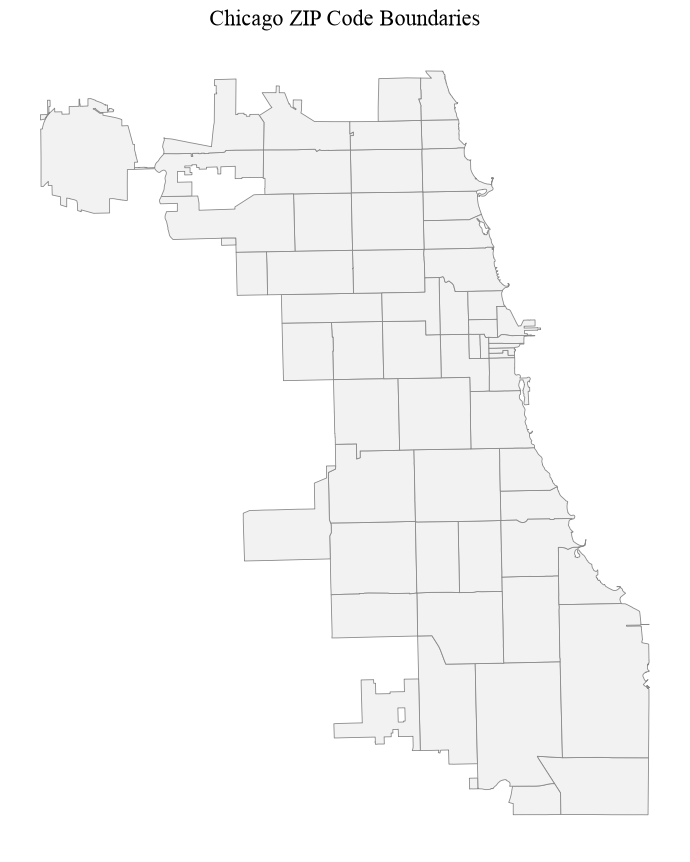

In [18]:
import geopandas as gpd
import matplotlib.pyplot as plt

zip_boundaries = gpd.read_file(boundary_path)

print("Boundary records: ", len(zip_boundaries))
print("Columns: ", zip_boundaries.columns.tolist())
print("CRS: ", zip_boundaries.crs)

display(zip_boundaries.head())

# Preview ZIP boundaries
fig, ax = plt.subplots(figsize=(7, 10))

zip_boundaries.plot(
    ax=ax,
    facecolor="#F2F2F2",
    edgecolor="#888888",
    linewidth=0.6
)

ax.set_title("Chicago ZIP Code Boundaries", fontsize=16)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [19]:
import pandas as pd
import geopandas as gpd

# Standardise ZIP codes, including forms such as 60607 and 60607.0
def clean_zip(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
        .where(lambda x: x.str.fullmatch(r"\d{5}", na=False))
    )

# Use the cleaned inspection table
map_inspections = inspection.copy()

map_inspections["Zip"] = clean_zip(map_inspections["Zip"])
map_inspections["Inspection Date"] = pd.to_datetime(
    map_inspections["Inspection Date"], errors="coerce"
)

# Match the report's date range and failure-rate definition
eligible = map_inspections.loc[
    map_inspections["Inspection Date"].ge("2020-01-01")
    & map_inspections["Inspection Date"].lt("2026-10-06")
    & map_inspections["Results"].isin(
        ["Pass", "Pass w/ Conditions", "Fail"]
    )
    & map_inspections["Zip"].notna()
].copy()

completed = eligible.groupby("Zip")["Inspection ID"].nunique()

failed = (
    eligible.loc[eligible["Results"].eq("Fail")]
    .groupby("Zip")["Inspection ID"]
    .nunique()
)

zip_summary = pd.DataFrame({
    "Completed": completed,
    "Failed": failed.reindex(completed.index, fill_value=0)
}).reset_index()

zip_summary["Failure_rate"] = (
    zip_summary["Failed"] / zip_summary["Completed"]
)

zip_summary["Rate_display"] = zip_summary["Failure_rate"].where(
    zip_summary["Completed"].ge(100)
)

# Retain the required boundary fields
boundaries = zip_boundaries[["zip", "geometry"]].copy()
boundaries["Zip"] = clean_zip(boundaries["zip"])
boundaries = boundaries.dropna(subset=["Zip"])

# Dissolve multiple polygons sharing a ZIP code
boundaries = boundaries[["Zip", "geometry"]].dissolve(
    by="Zip", as_index=False
)

map_data = boundaries.merge(
    zip_summary,
    on="Zip",
    how="left",
    validate="one_to_one"
)

# Use a projected coordinate system suitable for Chicago
map_data = map_data.to_crs(epsg=26916)

# Check eligible ZIP codes without matching boundaries
unmatched = zip_summary.loc[
    zip_summary["Completed"].ge(100)
    & ~zip_summary["Zip"].isin(boundaries["Zip"]),
    ["Zip", "Completed", "Failure_rate"]
]

print("ZIP areas with displayed failure rates: ", map_data["Rate_display"].notna().sum())
print("ZIP codes with at least 100 inspections but no matching boundary: ")
display(unmatched)

ZIP areas with displayed failure rates:  59
ZIP codes with at least 100 inspections but no matching boundary: 


,Zip,Completed,Failure_rate


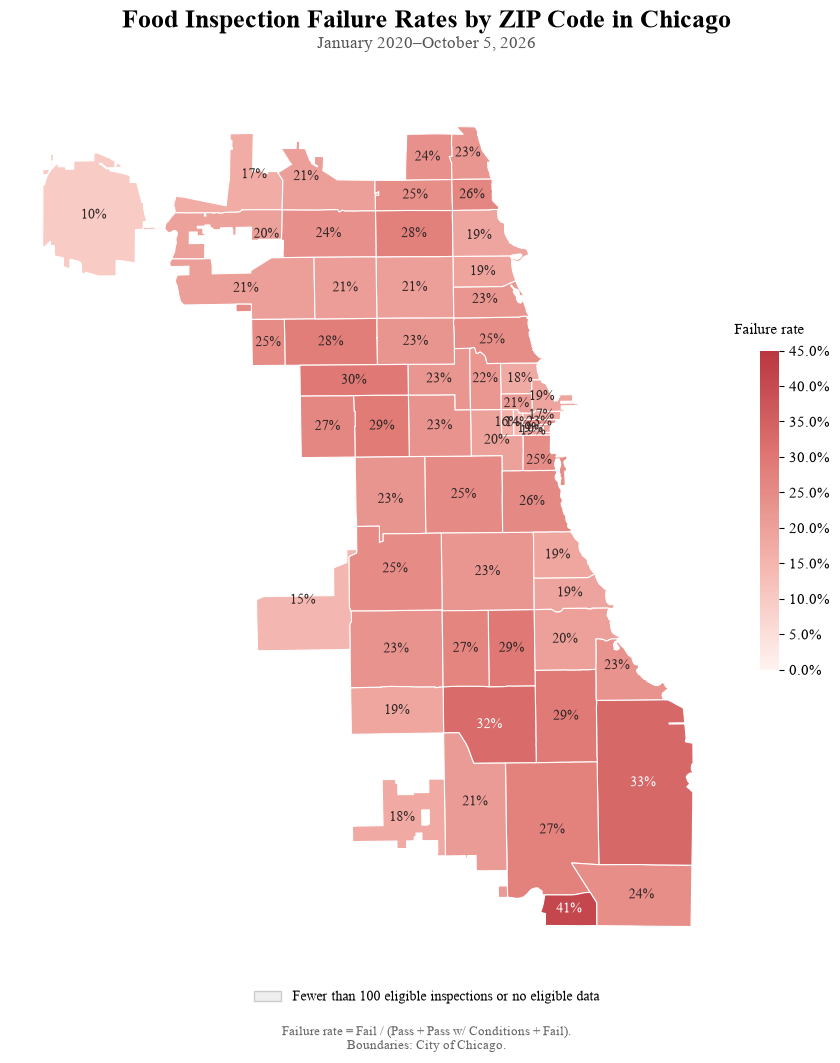

In [20]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch
from pathlib import Path
import numpy as np

plt.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig, ax = plt.subplots(figsize=(9, 11))
fig.subplots_adjust(left=0.03, right=0.84, top=0.90, bottom=0.10)

# Draw all ZIP areas with a light-grey background
map_data.plot(
    ax=ax,
    color="#EEEEEE",
    edgecolor="white",
    linewidth=0.8
)

valid = map_data.loc[map_data["Rate_display"].notna()].copy()

if valid.empty:
    raise ValueError("No ZIP areas have at least 100 inspections and a matching boundary. Check the data.")

# Use a continuous scale starting at zero and round its maximum up to five percentage points
vmax = max(
    0.05,
    np.ceil(valid["Rate_display"].max() / 0.05) * 0.05
)
norm = mcolors.Normalize(vmin=0, vmax=vmax)

cmap = mcolors.LinearSegmentedColormap.from_list(
    "failure_red",
    ["#FFF3F0", "#F4B5AE", "#DF7773", "#B93640"]
)

valid.plot(
    ax=ax,
    column="Rate_display",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.8
)

# Place labels at representative points inside polygons
label_points = valid.geometry.representative_point()

for (_, row), point in zip(valid.iterrows(), label_points):
    rate = row["Rate_display"]

    ax.text(
        point.x,
        point.y,
        f"{rate:.0%}",
        ha="center",
        va="center",
        fontsize=10,
        color="white" if norm(rate) >= 0.72 else "#302626"
    )

# Colour bar
cax = fig.add_axes([0.87, 0.37, 0.022, 0.29])

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
cbar.ax.set_title("Failure rate", fontsize=11, pad=12)
cbar.outline.set_visible(False)

fig.suptitle(
    "Food Inspection Failure Rates by ZIP Code in Chicago",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5, 0.935,
    "January 2020–October 5, 2026",
    ha="center",
    fontsize=12,
    color="#555555"
)

ax.set_axis_off()

fig.legend(
    handles=[
        Patch(
            facecolor="#EEEEEE",
            edgecolor="#CCCCCC",
            label="Fewer than 100 eligible inspections or no eligible data"
        )
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.055),
    frameon=False,
    fontsize=10
)

fig.text(
    0.5, 0.025,
    "Failure rate = Fail / (Pass + Pass w/ Conditions + Fail).\n"
    "Boundaries: City of Chicago.",
    ha="center",
    fontsize=9,
    color="#666666"
)

output_dir = Path(
    "outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "ZIP_Failure_Rate_Map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    output_dir / "ZIP_Failure_Rate_Map.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()